<a href="https://colab.research.google.com/github/fxrdhan/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_01_Exploratory_Data_Analysis/Chapter_01_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 1 — Exploratory Data Analysis

| | |
|---|---|
| **Book** | *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition — Peter Bruce, Andrew Bruce and Peter Gedeck (O'Reilly Media, 2020) |
| **Code reproduced here** | the Python code of the book's official repository, `gedeck/practical-statistics-for-data-scientists` (GNU General Public License v3) |
| **Versions used to run this notebook** | printed by the setup cell |
| **What this notebook contains** | a summary of every section of the chapter, the theory behind it, the book's Python code reproduced with an analysis of every output, and extra experiments written for this notebook |

## Chapter overview

Exploratory data analysis (EDA) is the first step of every analysis: before any model, look at the data. The chapter follows John Tukey's idea (Tukey, 1977) that data should be *explored* with simple summaries and pictures before they are *confirmed* with formal inference. It introduces the vocabulary of **structured data** (the types of variable and the rectangular table that holds them), then the numbers that summarize one variable (**location** and **variability**), the pictures that show its **distribution**, the summaries for **binary and categorical** data, and finally the tools that relate two or more variables: **correlation**, **hexagonal binning**, **contingency tables**, **boxplots and violin plots**, and **conditional (faceted) plots**.

### Sections of this chapter

| # | Section of the book | Python code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Elements of structured data | no code | a statistical type for the main variables of the datasets, and the numeric column that is not a number (ZIP codes) |
| 2 | Rectangular data | no code | the shape, the index, the missing values and the wide against long layouts of the datasets of the chapter |
| 3 | Estimates of location | mean, trimmed mean, median, weighted mean, weighted median | why the mean and the median minimize different losses, how many outliers each estimate survives, the trimming proportion, a weighted median by hand, efficiency against robustness |
| 4 | Estimates of variability | standard deviation, IQR, MAD | the $n-1$ divisor by simulation, the scale constants that make IQR and MAD comparable with the standard deviation, the effect of outliers |
| 5 | Exploring the data distribution | percentiles, boxplots, frequency tables, histograms, density plots | the nine definitions of a percentile, a boxplot by hand, rules for the number of bins, the bandwidth of a density estimate |
| 6 | Exploring binary and categorical data | frequency table, bar chart | the mode and the expected value of a categorical variable, a Pareto chart |
| 7 | Correlation | correlation matrix, heatmap, ellipse plot, scatterplot | the formula by hand, Spearman and Kendall, Anscombe's quartet, a confidence interval, spurious correlation of random walks |
| 8 | Exploring two or more variables | hexagonal binning, contour plot, contingency table, boxplot, violin plot, facets | overplotting, a chi-square test and Cramér's $V$ for a contingency table, group-wise slopes |

### How to read this notebook

Every section has the same structure:

1. **Summary** — what the book says, condensed in my own words (the book itself is not quoted).
2. **Theory** — the ideas behind it: definitions, math and the reasons that make a method behave as it does.
3. **Book code** — the official Python code of the chapter, reproduced and executed, followed by an **output analysis**.
4. **Extra** — experiments written for this notebook. They are *not* part of the book. They are lettered (a), (b), ... in order; sections 1 and 2 share one sequence, as do sections 7 and 8, and they are always cited with the section number, as in 3(b).

Every code cell starts with a label comment: `# BOOK CODE` for code of the official repository, `# EXTRA` for code written for this notebook. The book's code is reproduced as it is; where it needs a change to run in a notebook, the change is marked in the cell.

---
## 0. Setup

The datasets of the book live in the official repository, in its `data` folder. The helper `ensure_data` below looks for each file in a folder called `data` next to the notebook and **downloads it from the official repository the first time** it is missing (this is the only use of the network; the folder is not part of this repository, see `.gitignore`). The datasets used by this chapter are small, except `sp500_data.csv.gz` (about 21 MB).

The setup cell also installs `wquantiles` if it is missing (a fresh environment, or Google Colab, may not have it), prints the versions of the libraries, because the code of the book was written for older ones, and sets a quiet plotting style (it is global, so it also applies to the figures of the book code).

In [1]:
# SETUP
import importlib.util
import platform
import subprocess
import sys
import urllib.request
import warnings
from pathlib import Path

# a fresh environment may not have `wquantiles` (the weighted median of section 3); install it when it is missing
if importlib.util.find_spec("wquantiles") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wquantiles"])

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import statsmodels
import wquantiles

print(f"Python       : {platform.python_version()}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"statsmodels  : {statsmodels.__version__}")
print(f"seaborn      : {sns.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# --- the datasets of the official repository ---------------------------------------------------------
DATA = Path("data")
DATA_URL = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"


def ensure_data(*names):
    """Make sure that the files `names` exist in the folder `data`; download the missing ones."""
    DATA.mkdir(exist_ok=True)
    for name in names:
        if not (DATA / name).exists():
            urllib.request.urlretrieve(DATA_URL + name, DATA / name)
    return DATA


ensure_data("state.csv", "dfw_airline.csv", "airline_stats.csv", "kc_tax.csv.gz", "lc_loans.csv",
            "sp500_data.csv.gz", "sp500_sectors.csv")

# --- a quiet, colour-blind-safe style (global: it also applies to the figures of the book code) -------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
NumPy        : 2.5.4
pandas       : 3.1.0
SciPy        : 1.16.3
statsmodels  : 0.15.0
seaborn      : 0.13.2
Matplotlib   : 3.11.2


---
## 1. Elements of structured data

*Book section: "Elements of Structured Data". The section has no code.*

### Summary

* Data come from many sources (sensors, text, images, transactions); the chapter and the book deal with **structured data**, data that fit into a table with one row per record and one column per variable.
* Structured data are **numeric** or **categorical**.
    * Numeric data are **continuous** (any value in an interval, such as a temperature or a waiting time) or **discrete** (whole-number counts, such as visits per day).
    * Categorical data take a fixed set of values: a **binary** variable has two (yes or no, 0 or 1), an **ordinal** one has categories with a natural order (a satisfaction scale, a loan grade).
* The type matters because software chooses its computations and its plots from it, and because many analyses are only meaningful for some types: the mean of a category code is meaningless. A data scientist often goes beyond the type that the software has stored (for example storing an ordinal variable as an ordered category lets models use the order).
* Terms of this section: *numeric*, *continuous*, *discrete*, *categorical*, *binary*, *ordinal*.

### Theory

**Stevens' scales of measurement.** The classification above is close to the four *levels of measurement* proposed by Stevens (1946) (a link made by this notebook, not by the book), each defined by the transformations that leave its information unchanged and therefore by the operations that are meaningful:

| Level | Information | Meaningful operations | Typical summary | Example |
|---|---|---|---|---|
| Nominal | names only | equality, counting | mode, proportions | airline, state, ZIP code |
| Ordinal | names and order | the above and ranking | median, percentiles | loan grade A to G |
| Interval | order and equal differences, no true zero | the above and addition, subtraction | mean, standard deviation | a temperature in degrees Celsius |
| Ratio | order, differences and a true zero | the above and ratios | all, including the coefficient of variation | a population, a price, a duration |

Binary variables are a nominal variable with two values (and also the special case of a 0/1 count, which makes the mean of a binary variable a *proportion*). The distinction between continuous and discrete is about how many values are possible; in practice a discrete count with many distinct values (a population in the millions) is treated as continuous.

**Type is a property of meaning, not of storage.** A ZIP code is stored as a number but is a *name*: adding two ZIP codes or averaging them has no meaning, and the order of the codes carries no information about distance. The mirror case is an ordinal grade stored as text (`'A'`, `'B'`, ...): sorting alphabetically happens to respect the order here, but a rating stored as `'low'`, `'medium'`, `'high'` sorts wrongly. In `pandas` the way to record the real type is the `category` dtype (ordered or not), which also stores each distinct label only once.

**Why the type controls the analysis.** The summaries of the next sections each assume a level: the mean and the standard deviation assume interval data, while the median and the IQR need only an order; a bar chart and a mode are for nominal data; an ordinal variable supports the median and percentiles but not the mean without an extra assumption (that the steps between grades are equal). Treating a nominal variable as a number is the error that the extra below makes visible.

### Extra experiments

**(a) A statistical type for the main variables of the chapter.** The four main datasets of Chapter 1 (the states, the loans, the airlines and the tax data) are loaded and every column is listed with its `pandas` dtype, its number of distinct values, its share of missing values and the **statistical type** that this notebook assigns to it (my judgment, with the reason). The loan table has 450,961 rows and the tax table 498,249.

In [2]:
# EXTRA (a): the variables of the chapter, their storage type and their statistical type
state = pd.read_csv(DATA / "state.csv")
lc_loans = pd.read_csv(DATA / "lc_loans.csv")
airline_stats = pd.read_csv(DATA / "airline_stats.csv")
kc_tax = pd.read_csv(DATA / "kc_tax.csv.gz")
dfw = pd.read_csv(DATA / "dfw_airline.csv")

judgment = {
    ("state", "State"): ("nominal", "the name of a state"),
    ("state", "Population"): ("ratio, discrete", "a count with a true zero; with values in the millions it is treated as continuous"),
    ("state", "Murder.Rate"): ("ratio, continuous", "murders per 100,000 inhabitants"),
    ("state", "Abbreviation"): ("nominal", "a two-letter code, one per state"),
    ("lc_loans", "status"): ("nominal", "four unordered states of a loan"),
    ("lc_loans", "grade"): ("ordinal", "grades A to G, ordered from the least to the most risky"),
    ("airline_stats", "pct_carrier_delay"): ("ratio, continuous", "a daily percentage of flights"),
    ("airline_stats", "pct_atc_delay"): ("ratio, continuous", "a daily percentage of flights"),
    ("airline_stats", "pct_weather_delay"): ("ratio, continuous", "a daily percentage of flights"),
    ("airline_stats", "airline"): ("nominal", "six carriers"),
    ("kc_tax", "TaxAssessedValue"): ("ratio, continuous", "a value in dollars"),
    ("kc_tax", "SqFtTotLiving"): ("ratio, continuous", "an area, measured in square feet and rounded to whole numbers"),
    ("kc_tax", "ZipCode"): ("nominal", "a name stored as a number"),
}
rows = []
for name, df in (("state", state), ("lc_loans", lc_loans), ("airline_stats", airline_stats), ("kc_tax", kc_tax)):
    for column in df.columns:
        kind, why = judgment[(name, column)]
        rows.append({"table": name, "column": column, "pandas dtype": str(df[column].dtype), "distinct values": df[column].nunique(),
                     "missing": f"{df[column].isna().mean():.1%}", "statistical type": kind, "reason": why})
print(pd.DataFrame(rows).to_string(index=False))

        table            column pandas dtype  distinct values missing  statistical type                                                                            reason
        state             State          str               50    0.0%           nominal                                                               the name of a state
        state        Population        int64               50    0.0%   ratio, discrete a count with a true zero; with values in the millions it is treated as continuous
        state       Murder.Rate      float64               34    0.0% ratio, continuous                                                   murders per 100,000 inhabitants
        state      Abbreviation          str               50    0.0%           nominal                                                  a two-letter code, one per state
     lc_loans            status          str                4    0.0%           nominal                                                   four unorder

**Analysis of extra (a).**

* **Storage type and statistical type are different things.** `ZipCode` is a `float64` but a nominal variable; `grade` is text (`str`) but ordinal; `Population` and `SqFtTotLiving` are integers, yet the first is treated as continuous (50 different values, in the millions) and the second is an area rounded to whole square feet, a measurement and not a count. No dtype separates nominal from ordinal: `status` and `grade` are both `str`, and only the judgment in the table records that one has an order and the other has not.
* **Why is `ZipCode` a float?** With the default dtypes an integer column that contains missing values cannot stay an integer in `pandas` (there is no integer `NaN`), so `read_csv` stores it as `float64`. The 6.1% of missing ZIP codes is the reason; `SqFtTotLiving` has no missing value and remains `int64`.
* **Ties and resolution.** `Murder.Rate` has only 34 distinct values among the 50 states, because it is rounded to one decimal and many states are tied; the three daily delay percentages have 18,090 to 26,916 distinct values in 33,468 rows. The number of distinct values is the first hint of how much ties will matter for the percentiles, bins and densities of section 5.
* **Missing values.** Only `ZipCode` has a noticeable share (6.1%); every other column is at 0.1% or below. Where the missing values are is the subject of extra 2(c).

**(b) The numeric column that is not a number.** `ZipCode` is stored as a floating-point number. The cell computes its mean (which software happily does), counts the distinct codes, and compares the memory used by text and by the `category` dtype for the two label columns of the loan table, which have only 4 and 7 distinct values among 450,961 rows.

In [3]:
# EXTRA (b): a nominal variable stored as a number, and the category dtype
zip_codes = kc_tax["ZipCode"].dropna()
print(f"mean of the ZIP codes: {zip_codes.mean():.2f}   (a number that is not the code of any place)")
print(f"distinct ZIP codes   : {zip_codes.nunique()}, from {int(zip_codes.min())} to {int(zip_codes.max())}")
print(f"share of the non-missing codes that belong to the five most frequent ZIP codes: {zip_codes.value_counts(normalize=True).head(5).sum():.1%}")
inside = zip_codes.between(98000, 98999)
print(f"{int((~inside).sum())} of {len(zip_codes):,} codes lie outside 98000-98999; the mean of the others is {zip_codes[inside].mean():.2f}")
print("the codes outside that range:", sorted(int(code) for code in zip_codes[~inside]))

rows = []
for column in ("status", "grade"):
    as_text = lc_loans[column].memory_usage(deep=True)
    as_category = lc_loans[column].astype("category").memory_usage(deep=True)
    rows.append({"column": column, "distinct values": lc_loans[column].nunique(), "memory as text (MB)": as_text / 1e6,
                 "memory as category (MB)": as_category / 1e6, "reduction": as_text / as_category})
print()
print(pd.DataFrame(rows).round(3).to_string(index=False))

grades = pd.Categorical(lc_loans["grade"], categories=list("ABCDEFG"), ordered=True)
print("\nordered category: grade 'B' < 'E' is", bool(pd.Categorical(["B"], categories=list("ABCDEFG"), ordered=True)[0] < "E"),
      "| lowest grade present:", grades.min(), "| highest:", grades.max())

mean of the ZIP codes: 98309.35   (a number that is not the code of any place)
distinct ZIP codes   : 116, from 0 to 98157059
share of the non-missing codes that belong to the five most frequent ZIP codes: 13.5%
14 of 467,900 codes lie outside 98000-98999; the mean of the others is 98079.91
the codes outside that range: [0, 98, 9800, 9804, 89118, 90055, 90108, 90855, 95055, 95059, 95125, 99019, 9806501, 98157059]

column  distinct values  memory as text (MB)  memory as category (MB)  reduction
status                4               25.607                    0.451     56.738
 grade                7               22.548                    0.451     49.947

ordered category: grade 'B' < 'E' is True | lowest grade present: A | highest: G


**Analysis of extra (b).**

* **The mean of a name.** The mean of the ZIP codes is 98,309.35. Software computes it without complaint, and it is not the code of any place: the statistical type, not the dtype, tells that the operation is meaningless.
* **A high-cardinality nominal variable.** There are 116 distinct codes and the five most frequent cover 13.5% of the 467,900 non-missing codes: many levels and no dominant one.
* **A numeric dtype accepts anything.** 14 of the 467,900 codes lie outside the range 98000 to 98999 that holds the county's data. Eight of them (89118, 90055, 90108, 90855, 95055, 95059, 95125 and 99019) are well-formed five-digit codes of other places, plausible for owners who live elsewhere. The other six, 0, 98, 9800, 9804, 9806501 and 98157059, cannot be five-digit codes as written (the shorter ones may have lost a leading zero), so they are most likely entry errors that a numeric column cannot reject. Dropping all 14 moves the mean from 98,309.35 to 98,079.91, a reminder of how easily a few odd labels move an average of labels.
* **The `category` dtype.** Storing each distinct label once and keeping a one-byte code per row reduces the memory of `status` from 25.6 MB to 0.45 MB (a factor of 57) and of `grade` from 22.5 MB to 0.45 MB (a factor of 50). The factors depend on how the library stores text (here the `str` dtype of the installed `pandas`); the order of magnitude does not. An *ordered* category also makes comparisons meaningful: grade B is below grade E, and the lowest and highest grades present are A and G.

---
## 2. Rectangular data

*Book section: "Rectangular Data" (with "Data Frames and Indexes" and "Nonrectangular Data Structures"). The section has no code.*

### Summary

* The typical object of data science is a **rectangular** table, called a *data frame* in R and in `pandas`: **rows are records** (cases, observations, instances) and **columns are variables** (features, attributes, predictors).
* A data frame also has an **index**, a label for each row. In R and `pandas` it can be an integer position or a meaningful key such as a date; a good index makes selection and alignment fast. A row-index that carries meaning is used, for example, by the stock-price table of the chapter, whose rows are dates.
* Terminology differs between fields: statisticians speak of *predictor* and *response*, computer scientists of *feature* and *outcome*, and a *record* is also an *example* or *sample*. The word *sample* is used in both ways: a collection of rows for a statistician, a single row in some computing usage.
* Not all data are rectangular: **time series** (an ordered sequence of measurements of one variable), **spatial** data (maps, objects, fields) and **graphs** (networks of relations between entities) are other structures; they are usually converted to a table for analysis.
* Terms of this section: *data frame*, *feature*, *outcome*, *record*, *index*, *time series*, *spatial*, *graph*.

### Theory

**Tidy data.** Wickham (2014) formalized what makes a rectangular table convenient: each **variable is a column**, each **observation is a row**, and each *type of observational unit* has its own table. Most analysis code (grouping, plotting, modelling) assumes this *long* layout. Data are often delivered in a *wide* layout, where the values of one variable are spread over several columns (one column per cause of delay, one column per year), or where one table mixes two levels of observation. Reshaping from wide to long (`melt`) and back (`pivot`) is the first step of many analyses.

**The role of the index.** An index maps a label to a row position. A *unique, sorted* index (dates in increasing order) lets a library select a range with a binary search instead of scanning every row, and makes arithmetic between two frames **align by label** rather than by position. The default integer index (0, 1, 2, ...) has no meaning of its own and is not a variable.

**Missing values.** A cell may have no value. A rectangular table stores that as a special marker (`NaN`, `NA`). Their effect depends on why they are missing. Rubin (1976) distinguished three mechanisms: *missing completely at random* (the absence is unrelated to the data), *missing at random* (it depends only on variables that are observed) and *missing not at random* (it depends on the missing value itself). The first is harmless for simple summaries apart from the loss of data; with the other two a summary of the complete rows can be biased unless the mechanism is taken into account. The first exploratory step is to **count them per column and see where they are**; summaries then either skip them (the default of `pandas`) or must handle them explicitly.

**Memory and size.** A rectangular table of $n$ rows and $p$ columns of 8-byte numbers uses $8np$ bytes; the stock table of the chapter has 5,647 rows and 517 columns, about 23 MB. Object-valued (text) columns cost more, which is why repeating labels are better stored as categories (extra 1(b)).

### Extra experiments

**(c) Shape, index, missing values.** The cell prints the shape and the index of the tables of the chapter, shows where the missing values of the airline and tax tables are, and checks that the dates of the stock table are a sorted and unique index.

In [4]:
# EXTRA (c): shape, index and missing values of the tables of the chapter
sp500_px = pd.read_csv(DATA / "sp500_data.csv.gz", index_col=0)
sp500_sym = pd.read_csv(DATA / "sp500_sectors.csv")

tables = {"state": state, "lc_loans": lc_loans, "airline_stats": airline_stats, "kc_tax": kc_tax, "sp500_px": sp500_px, "sp500_sym": sp500_sym, "dfw": dfw}
summary = pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1], "index": f"{type(df.index).__name__}, {df.index[0]!s} to {df.index[-1]!s}",
                               "missing cells": int(df.isna().sum().sum()), "memory (MB)": df.memory_usage(deep=True).sum() / 1e6}
                        for name, df in tables.items()}).T
print(summary.to_string())

print("\nmissing values per column")
print(pd.concat({"airline_stats": airline_stats.isna().sum(), "kc_tax": kc_tax.isna().sum()}).to_string())
rows_missing = kc_tax["TaxAssessedValue"].isna()
print(f"\nkc_tax: rows without TaxAssessedValue {rows_missing.mean():.1%}; their median area {kc_tax.loc[rows_missing, 'SqFtTotLiving'].median():.0f} sq ft "
      f"against {kc_tax.loc[~rows_missing, 'SqFtTotLiving'].median():.0f} for the others")
print(f"airline_stats: the {airline_stats['pct_carrier_delay'].isna().sum()} missing pct_carrier_delay values belong to", airline_stats.loc[airline_stats['pct_carrier_delay'].isna(), 'airline'].value_counts().to_dict())
delay_columns = ["pct_carrier_delay", "pct_atc_delay", "pct_weather_delay"]
print(f"days with a missing value in at least one delay column: {int(airline_stats[delay_columns].isna().any(axis=1).sum())}; in all three: {int(airline_stats[delay_columns].isna().all(axis=1).sum())}; days per airline: {airline_stats['airline'].value_counts().to_dict()}")

dates = pd.to_datetime(sp500_px.index)
print(f"\nsp500_px index: {len(dates)} dates, unique {dates.is_unique}, increasing {dates.is_monotonic_increasing}; "
      f"first {dates[0].date()}, last {dates[-1].date()}")

                 rows columns                            index missing cells memory (MB)
state              50       4              RangeIndex, 0 to 49             0    0.006354
lc_loans       450961       2          RangeIndex, 0 to 450960             0   48.155263
airline_stats   33468       4           RangeIndex, 0 to 33467            84    2.670749
kc_tax         498249       3          RangeIndex, 0 to 498248         31087   11.958108
sp500_px         5647     517  Index, 1993-01-29 to 2015-07-01             0   23.689165
sp500_sym         517       4             RangeIndex, 0 to 516             0    0.127411
dfw                 1       5               RangeIndex, 0 to 0             0    0.000172

missing values per column
airline_stats  pct_carrier_delay       28
               pct_atc_delay           28
               pct_weather_delay       28
               airline                  0
kc_tax         TaxAssessedValue       738
               SqFtTotLiving            0
         

**Analysis of extra (c).**

* **Sizes.** The tax table is the largest (498,249 rows), the loan table has 450,961 rows, and the stock table is the widest: 5,647 dates by 517 columns, 23.7 MB, which is close to the 23.4 MB that $5{,}647 \times 517$ eight-byte numbers need. The airport table has one row and five columns, the wide layout that extra 2(d) reshapes.
* **Where the values are missing.** The tax table has 31,087 missing cells, 30,349 in `ZipCode` and 738 in `TaxAssessedValue`. The airline table has 84, which are 28 in each of the three delay columns, and the cell shows that they are the same 28 days. They are few: Delta and United have 12 each and Jet Blue and American 2 each, so the gaps are not proportional to the volume of data (United, with 5,426 days, has as many as Delta, with 9,107).
* **Missing is not always random.** The 0.1% of tax records without an assessed value have a median area of 1,345 square feet, against 1,900 for the others: they are smaller properties. Dropping them is harmless here because there are so few, but with a larger share the same difference would bias the estimates toward larger houses.
* **The index of the stock table.** Its 5,647 dates are unique and increasing, from 1993-01-29 to 2015-07-01. In the book code the index is read as text, not as dates; selecting the rows after `'2012-07-01'` still works because ISO dates sort in the same order as text.

**(d) Wide against long.** The table of delay causes at Dallas/Fort Worth (`dfw_airline.csv`) is **wide**: one row and one column per cause. The cell reshapes it into the **long** layout with one row per cause, the layout that plotting and grouping code expects, and checks that nothing is lost.

In [5]:
# EXTRA (d): the wide table of delay causes and its long (tidy) form
long = dfw.melt(var_name="cause", value_name="delays")
long["share"] = long["delays"] / long["delays"].sum()
print("wide:", dfw.shape)
print(dfw.to_string(index=False))
print("\nlong:", long.shape)
print(long.round(4).to_string(index=False))
back = long.pivot_table(columns="cause", values="delays")[dfw.columns]
print("\nround trip back to the wide layout is exact:", np.allclose(back.to_numpy(), dfw.to_numpy()))

wide: (1, 5)
 Carrier     ATC  Weather  Security   Inbound
64263.16 84856.5 11235.42    343.15 118427.82

long: (5, 3)
   cause    delays  share
 Carrier  64263.16 0.2302
     ATC  84856.50 0.3040
 Weather  11235.42 0.0403
Security    343.15 0.0012
 Inbound 118427.82 0.4243

round trip back to the wide layout is exact: True


**Analysis of extra (d).**

* The wide table (1 row, 5 columns) becomes a long table with one row per cause and a `share` column. The five values add up to about 279,126, and the shares are the percentages of Table 1-6 that section 6 reproduces: inbound 42.4%, air traffic control 30.4%, carrier 23.0%, weather 4.0% and security 0.1%.
* The round trip back to the wide layout is exact (`np.allclose` is `True`), so reshaping loses nothing. The long layout can go directly to `groupby` or to a plotting function that takes a category on one axis.
* The values are not whole numbers (64,263.16 for the carrier), so they cannot be raw counts of flights; the axis label *Count* of the book's chart is loose. Only the proportions matter for the analysis.

---
## 3. Estimates of location

*Book section: "Estimates of Location" (mean, weighted mean, median and robust estimates, example of the population and murder rates of the states).*

### Summary

* The first thing to know about a variable is where its values are centered: its **location** or *central tendency*. Statisticians call a number computed from a sample an **estimate** (of an unknown value of the population), data scientists often call it a *metric*; the book uses both.
* The **mean** is the sum of the values divided by their number. The **trimmed mean** drops a fixed share of the smallest and of the largest values before averaging, which removes the pull of extreme values. The **weighted mean** gives each value a weight, for example to take the size of a group into account.
* The **median** is the value in the middle of the sorted data (the average of the two middle values if their number is even); it depends only on the position of the data, not on the size of the extreme ones. The **weighted median** is the value such that half of the total weight lies on each side.
* An **outlier** is a value that is very different from most of the data. Estimates that are not much affected by outliers are called **robust**. The median and the trimmed mean are robust; the mean is not. Choosing between them is a trade-off between robustness and efficiency (see the theory below), and the trimmed mean is a common compromise.
* **Example.** For the populations of the 50 states, the mean (about 6.16 million) is far above the trimmed mean (4.78 million) and the median (4.44 million), because a few large states pull the mean up. For the murder rates the mean of the states is 4.07 per 100,000, the population-weighted mean is 4.45 and the weighted median 4.4: the weighted values describe the country, not the average state.
* Terms of this section: *mean*, *weighted mean*, *median*, *weighted median*, *trimmed mean*, *robust*, *outlier*.

### Theory

**Location as the solution of a minimization problem.** An estimate of the center is the constant $c$ that is closest to all the data, and the notion of "close" is a loss function:
$$\bar{x} = \arg\min_c \sum_{i=1}^{n} (x_i - c)^2, \qquad \operatorname{median}(x) \in \arg\min_c \sum_{i=1}^{n} |x_i - c|.$$
For the squared loss, setting the derivative $-2\sum (x_i - c)$ to zero gives $c = \sum x_i / n$, the mean. For the absolute loss the derivative is $-\sum \operatorname{sign}(x_i - c)$, which is zero when as many points lie above $c$ as below it: the median (for an even $n$, every value between the two middle ones is a minimizer and the convention picks their midpoint). The squared loss punishes a large deviation quadratically, so a distant point pulls the minimizer toward itself; the absolute loss punishes it linearly, so the pull is bounded. That one difference explains all the behavior of the two estimates below.

**Weighted estimates.** The weighted mean is $\bar{x}_w = \sum w_i x_i / \sum w_i$. Weights express unequal importance (the population of a state), unequal precision (inverse-variance weights make the estimate optimal when observations have different variances) or the design of a survey. The **weighted median** is the smallest value $x_{(j)}$ of the sorted data whose cumulative weight reaches half of the total, $\sum_{i \le j} w_{(i)} \ge \tfrac12 \sum w_i$. With equal weights it is the median (up to the convention for an even number of values).

**Trimmed and Winsorized means.** The $p$-trimmed mean averages the data left after removing the $\lfloor pn \rfloor$ smallest and the $\lfloor pn \rfloor$ largest values; $p = 0$ is the mean and $p \to 0.5$ approaches the median, so the family interpolates between the two. The *Winsorized* mean replaces the removed values by the nearest kept one instead of dropping them. Both are *L-estimators*, linear combinations of the order statistics.

**Robustness.** Two quantities describe how an estimate reacts to bad data. The **breakdown point** is the smallest share of observations that can be replaced by arbitrary values to make the estimate arbitrarily wrong: $1/n$ (zero in the limit) for the mean, about $50\%$ for the median, $p$ for the $p$-trimmed mean. The **influence function** (Hampel, 1974) is the effect on the estimate of adding one observation at value $x$: it is a straight line, unbounded, for the mean and a bounded step for the median.

**Efficiency against robustness.** When the data are exactly normal, the sample median has a sampling variance larger than the mean's by a factor $\pi/2 \approx 1.57$ (an asymptotic efficiency of $2/\pi \approx 0.64$): the mean uses the data better. When a few per cent of the observations come from a distribution with a much larger spread (Tukey's *contaminated normal* model, 1960), or when the tails are heavy, the ranking is reversed and the mean can be much worse than the median. Huber (1964) formalized this trade-off and proposed estimates, such as the Huber $M$-estimate, that are nearly as efficient as the mean for clean data and nearly as robust as the median for contaminated data. The trimmed mean is the simplest practical compromise, and extra 3(e) measures all three.

**Skewed data.** In a right-skewed distribution (population, income, prices) a few large values pull the mean above the median, so the two answer different questions: the mean is the "total divided by the count" (useful for planning and for sums), the median the value of a typical unit.

### Book code

The official script starts with the imports and the paths of the datasets (cell below; the book's helper `common` that finds the data folder is replaced by the `DATA` folder of the setup cell), and then follows the sections of the chapter. The cells of the next two sections reproduce it in order.

In [6]:
# BOOK CODE (imports and paths of the official script; `DATA` comes from the setup cell of this notebook)
from pathlib import Path

import pandas as pd
import numpy as np
from scipy.stats import trim_mean
from statsmodels import robust
import wquantiles

import seaborn as sns
import matplotlib.pylab as plt

# Define paths to data sets. If you don't keep your data in the same directory as the code, adapt the path names.

AIRLINE_STATS_CSV = DATA / 'airline_stats.csv'
KC_TAX_CSV = DATA / 'kc_tax.csv.gz'
LC_LOANS_CSV = DATA / 'lc_loans.csv'
AIRPORT_DELAYS_CSV = DATA / 'dfw_airline.csv'
SP500_DATA_CSV = DATA / 'sp500_data.csv.gz'
SP500_SECTORS_CSV = DATA / 'sp500_sectors.csv'
STATE_CSV = DATA / 'state.csv'

In [7]:
# BOOK CODE (Estimates of Location, Table 1-2): the population and murder rate of the states
state = pd.read_csv(STATE_CSV)
print(state.head(8))

         State  Population  Murder.Rate Abbreviation
0      Alabama     4779736          5.7           AL
1       Alaska      710231          5.6           AK
2      Arizona     6392017          4.7           AZ
3     Arkansas     2915918          5.6           AR
4   California    37253956          4.4           CA
5     Colorado     5029196          2.8           CO
6  Connecticut     3574097          2.4           CT
7     Delaware      897934          5.8           DE


In [8]:
# BOOK CODE (Estimates of Location): mean, trimmed mean and median of the population
state = pd.read_csv(STATE_CSV)
print(state['Population'].mean())

print(trim_mean(state['Population'], 0.1))

print(state['Population'].median())

6162876.3
4783697.125
4436369.5


In [9]:
# BOOK CODE (Estimates of Location): mean, weighted mean and weighted median of the murder rate
print(state['Murder.Rate'].mean())

print(np.average(state['Murder.Rate'], weights=state['Population']))

print(wquantiles.median(state['Murder.Rate'], weights=state['Population']))

4.066
4.445833981123393
4.4


**Output analysis.**

* **Location of the populations.** The mean is 6,162,876, the 10% trimmed mean 4,783,697 and the median 4,436,370. The mean is 39% above the median because a few very large states (California, Texas, New York, Florida) pull it up; trimming five states from each end brings the estimate most of the way to the median.
* **Murder rate.** The simple mean of the 50 rates is 4.066, the population-weighted mean 4.446 and the weighted median 4.4. Weighting raises the center because, in this table, the more populous states have on average higher rates than the small ones. The weighted median, 4.4, is the rate of California and Texas, which share it (extra 3(d)).
* The table printed first shows the structure of the data: one row per state with the population, the murder rate per 100,000 inhabitants and the abbreviation.

### Extra experiments

**(a) The mean and the median are minimizers of different losses.** For the murder rates of the 50 states, the cell evaluates the sum of squared deviations and the sum of absolute deviations on a fine grid of candidate centers $c$, finds the minimizer of each numerically, and compares them with the mean and the median. The figure shows the two loss curves.

squared loss : numerical minimizer 4.0660, mean   4.0660
absolute loss: numerical minimizer 4.0000, median 4.0000
loss at the mean, squared: 179.83; absolute loss at the mean 77.63 against 77.50 at the median

middle values of the murder rates: 4.0 and 4.0
middle values of the populations (millions): 4.339 and 4.533; absolute loss at the lower one, at the midpoint, at the upper one: 207.383, 207.383, 207.383


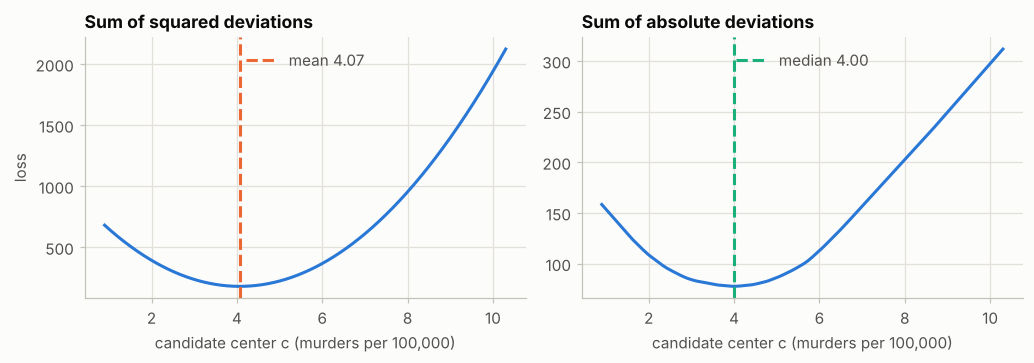

In [10]:
# EXTRA (a): the mean minimizes the squared loss, the median the absolute loss
from scipy.optimize import minimize_scalar

rate = state["Murder.Rate"].to_numpy()
candidates = np.linspace(rate.min(), rate.max(), 2001)
squared = np.array([np.sum((rate - c) ** 2) for c in candidates])
absolute = np.array([np.sum(np.abs(rate - c)) for c in candidates])

best_squared = minimize_scalar(lambda c: np.sum((rate - c) ** 2), bounds=(rate.min(), rate.max()), method="bounded").x
best_absolute = minimize_scalar(lambda c: np.sum(np.abs(rate - c)), bounds=(rate.min(), rate.max()), method="bounded").x
print(f"squared loss : numerical minimizer {best_squared:.4f}, mean   {rate.mean():.4f}")
print(f"absolute loss: numerical minimizer {best_absolute:.4f}, median {np.median(rate):.4f}")
print(f"loss at the mean, squared: {squared.min():.2f}; absolute loss at the mean {np.sum(np.abs(rate - rate.mean())):.2f} against {absolute.min():.2f} at the median")

# with an even number of values every c between the two middle values is a minimizer of the absolute loss;
# the murder rates have two equal middle values (no flat part), the populations have two different ones
millions = np.sort(state["Population"].to_numpy(float)) / 1e6
low, high = millions[24], millions[25]
flat = [np.sum(np.abs(millions - c)) for c in (low, (low + high) / 2, high)]
print(f"\nmiddle values of the murder rates: {np.sort(rate)[24]} and {np.sort(rate)[25]}")
print(f"middle values of the populations (millions): {low:.3f} and {high:.3f}; absolute loss at the lower one, at the midpoint, at the upper one: "
      f"{flat[0]:.3f}, {flat[1]:.3f}, {flat[2]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].plot(candidates, squared, color=PALETTE[0])
axes[0].axvline(rate.mean(), color=PALETTE[1], ls="--", label=f"mean {rate.mean():.2f}")
axes[0].set_title("Sum of squared deviations")
axes[1].plot(candidates, absolute, color=PALETTE[0])
axes[1].axvline(np.median(rate), color=PALETTE[2], ls="--", label=f"median {np.median(rate):.2f}")
axes[1].set_title("Sum of absolute deviations")
for ax in axes:
    ax.set_xlabel("candidate center c (murders per 100,000)")
    ax.legend(loc="upper center")
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.show()

**Analysis of extra (a).**

* The numerical minimizers agree with the closed forms to four decimals: 4.0660 for the squared loss (the mean) and 4.0000 for the absolute loss (the median). The loss at the mean is 179.83 in squared terms; in absolute terms the mean costs 77.63 against 77.50 at the median, a small difference because the mean and the median of the rates are close (4.07 and 4.00, a gap of 0.07 against a standard deviation of 1.9), although the rates are mildly right-skewed.
* The two curves differ in shape. The squared loss is a smooth parabola with one minimum. The absolute loss is made of straight segments with a kink at every observation, and its minimum can be flat: with an even number of values every point between the two middle ones is a minimizer. The murder rates have two equal middle values (4.0 and 4.0), so there is no flat part; the populations have two different ones (4.339 and 4.533 million), and the absolute loss is 207.383 at both and at their midpoint. The usual median, the midpoint, is a convention that picks one of infinitely many minimizers.
* The practical meaning: the squared loss punishes a large deviation much more than a small one, so the mean follows extreme values; the absolute loss grows only linearly, so a point pulls with the same force however far away it is, what counts is the side it lies on, and the median stays put.

**(b) How many outliers can each estimate survive?** The $k$ largest populations are replaced by an absurd value ($10^{12}$) for $k = 0, 1, 2, \dots$, and the mean, the 10% trimmed mean and the median are recomputed. The number of outliers at which each estimate is destroyed is its **breakdown point** in this sample of 50.

In [11]:
# EXTRA (b): breakdown of the mean, the trimmed mean and the median under k gross outliers
population = np.sort(state["Population"].to_numpy(float))
rows = []
for k in (0, 1, 2, 5, 6, 10, 24, 25):
    corrupted = population.copy()
    if k:
        corrupted[-k:] = 1e12
    rows.append({"outliers k": k, "share": k / len(population), "mean": corrupted.mean(), "10% trimmed mean": trim_mean(corrupted, 0.1), "median": np.median(corrupted)})
breakdown = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:,.4g}".format):
    print(breakdown.to_string(index=False))
print(f"\nthe 10% trimmed mean removes {int(0.1 * len(population))} values from each end; the median needs {len(population) // 2} outliers to break")

 outliers k  share      mean  10% trimmed mean    median
          0      0 6.163e+06         4.784e+06 4.436e+06
          1   0.02 2.001e+10         4.784e+06 4.436e+06
          2   0.04     4e+10         4.784e+06 4.436e+06
          5    0.1     1e+11         4.784e+06 4.436e+06
          6   0.12   1.2e+11           2.5e+10 4.436e+06
         10    0.2     2e+11          1.25e+11 4.436e+06
         24   0.48   4.8e+11          4.75e+11 4.436e+06
         25    0.5     5e+11             5e+11     5e+11

the 10% trimmed mean removes 5 values from each end; the median needs 25 outliers to break


**Analysis of extra (b).**

* **The mean breaks at once.** One value of $10^{12}$ takes the mean from $6.2 \times 10^{6}$ to $2.0 \times 10^{10}$; five of them (10% of the data) give $10^{11}$. Its breakdown point is one observation in 50, 2%.
* **The 10% trimmed mean survives 5 outliers and fails at 6.** It discards 5 values from each end, so up to 5 outliers are removed before the average is taken; the sixth is kept, and the estimate jumps to $2.5 \times 10^{10}$. Its breakdown point is its trimming proportion.
* **The median survives 24 outliers and fails at 25,** half of the sample. No estimate of location can do better than that.
* The value $10^{12}$ is absurd on purpose, to make the breaking visible. Real outliers are milder, so the table shows the worst case, not the usual one. The ranking mean, trimmed mean, median is the message, and its price is paid in efficiency (extra 3(e)).

**(c) The trimming proportion.** The trimmed mean of the populations is computed for every proportion $p$ from 0 to 0.48. The curve starts at the mean ($p = 0$) and ends near the median.

   p  trimmed mean (millions)
0.00                    6.163
0.02                    5.632
0.05                    5.316
0.10                    4.784
0.20                    4.414
0.30                    4.360
0.40                    4.281
0.48                    4.436
mean 6.163, median 4.436 (millions)


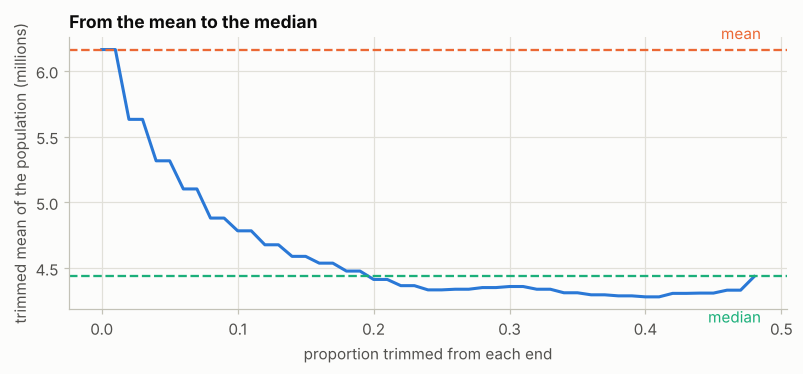

In [12]:
# EXTRA (c): the trimmed mean as a bridge between the mean and the median
proportions = np.linspace(0, 0.48, 49)
pop = state["Population"].to_numpy(float) / 1e6
curve = np.array([trim_mean(pop, p) for p in proportions])
print(pd.DataFrame({"p": [0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.48],
                    "trimmed mean (millions)": [trim_mean(pop, p) for p in (0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.48)]}).round(3).to_string(index=False))
print(f"mean {pop.mean():.3f}, median {np.median(pop):.3f} (millions)")

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(proportions, curve, color=PALETTE[0])
ax.axhline(pop.mean(), color=PALETTE[1], ls="--", lw=1.5)
ax.axhline(np.median(pop), color=PALETTE[2], ls="--", lw=1.5)
ax.text(0.485, pop.mean() + 0.08, "mean", color=PALETTE[1], ha="right")
ax.text(0.485, np.median(pop) - 0.35, "median", color=PALETTE[2], ha="right")
ax.set_xlabel("proportion trimmed from each end")
ax.set_ylabel("trimmed mean of the population (millions)")
ax.set_title("From the mean to the median")
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* The curve starts at the mean (6.163 million at $p = 0$) and falls fast: 5.632 at $p = 0.02$, when only California and Wyoming are removed, and 4.784 at $p = 0.10$.
* Most of the movement is over by $p = 0.2$ (4.414); from there the curve is nearly flat, a little below the median (about 4.28 at $p = 0.4$), because the middle 60% of the states are not perfectly symmetric around the median.
* At $p = 0.48$ only the two middle values remain and the trimmed mean equals the median, 4.436. A proportion of 0.1 to 0.2 is the usual compromise: it removes the influence of the large states and still uses most of the data.

**(d) A weighted median by hand, and what the weighted mean is.** The weighted median is computed from its definition (sort by murder rate, accumulate the populations, stop at half of the total) and compared with `wquantiles`. The cell also shows that the population-weighted mean is the murder rate of the whole country, by computing the total number of murders.

In [13]:
# EXTRA (d): the weighted median from its definition, and the weighted mean as a national rate
rates, weights = state["Murder.Rate"].to_numpy(), state["Population"].to_numpy(float)
total = weights.sum()
population_by_rate = pd.Series(weights).groupby(rates).sum()  # tied rates are pooled, so ties cannot change the result
cumulative = population_by_rate.cumsum() / total
weighted_median = cumulative.index[np.searchsorted(cumulative.to_numpy(), 0.5)]
print(f"weighted median by definition: {weighted_median} (population share of the states with a lower rate {weights[rates < weighted_median].sum() / total:.3f}, "
      f"with this rate or a lower one {cumulative.loc[weighted_median]:.3f}; states with this rate: {', '.join(state.loc[rates == weighted_median, 'State'])})")
print(f"wquantiles.median            : {wquantiles.median(rates, weights)}")
print(f"unweighted median            : {np.median(rates)}")

murders = (rates * weights / 100_000).sum()
print(f"\nmurders implied by the table: {murders:,.0f} among {weights.sum():,.0f} inhabitants -> {murders / weights.sum() * 100_000:.4f} per 100,000")
print(f"population-weighted mean     : {np.average(rates, weights=weights):.4f}")
print(f"simple mean of the 50 rates  : {rates.mean():.4f} (each state counts once, whatever its population)")

weighted median by definition: 4.4 (population share of the states with a lower rate 0.361, with this rate or a lower one 0.564; states with this rate: California, Texas)
wquantiles.median            : 4.4
unweighted median            : 4.0

murders implied by the table: 13,700 among 308,143,815 inhabitants -> 4.4458 per 100,000
population-weighted mean     : 4.4458
simple mean of the 50 rates  : 4.0660 (each state counts once, whatever its population)


**Analysis of extra (d).**

* The weighted median by definition is 4.4: 36.1% of the population lives in states with a lower rate and 56.4% in states with a rate of at most 4.4, so half of the population is reached at 4.4. Two states share that rate, California and Texas. `wquantiles.median` gives the same value. The unweighted median is 4.0.
* The weighted mean is the murder rate of the country: the table implies about 13,700 murders among 308,143,815 inhabitants, 4.4458 per 100,000, the same number as `np.average` with the population as weights. The simple mean, 4.066, treats Wyoming and California as equals and answers a different question (the typical state rather than the typical resident).

**(e) Efficiency against robustness.** For samples of $n = 100$ from three distributions that are all centered at 0 (the normal, a heavy-tailed $t$ distribution with 3 degrees of freedom, and a *contaminated normal*: 95% of the observations from $N(0,1)$ and 5% from $N(0, 10^2)$), the cell draws 5,000 samples from each, computes the mean, the 10% trimmed mean and the median of every sample, and reports the standard deviation of each estimate over the samples, relative to the mean. A value below 1 means that the estimate is more precise than the mean. The column `theory` is the exact standard deviation of the mean, $\sqrt{\mathrm{Var}(X)/n}$, as a check on the simulation.

In [14]:
# EXTRA (e): sampling variability of the mean, the trimmed mean and the median under three distributions
n, repetitions = 100, 5000
variance = {"normal": 1.0, "t with 3 degrees of freedom": 3.0, "contaminated normal": 0.95 * 1 + 0.05 * 100}


def draw(kind, rng):
    if kind == "normal":
        return rng.normal(size=(repetitions, n))
    if kind == "t with 3 degrees of freedom":
        return rng.standard_t(3, size=(repetitions, n))
    scale = np.where(rng.random((repetitions, n)) < 0.05, 10.0, 1.0)
    return rng.normal(size=(repetitions, n)) * scale


rows = []
for i, kind in enumerate(variance):
    samples = draw(kind, np.random.default_rng(2024 + i))  # one generator per distribution
    estimates = {"mean": samples.mean(1), "10% trimmed mean": trim_mean(samples, 0.1, axis=1), "median": np.median(samples, axis=1)}
    spread = {name: values.std(ddof=1) for name, values in estimates.items()}
    rows.append({"distribution": kind, "sd of the mean": spread["mean"], "theory": np.sqrt(variance[kind] / n),
                 **{f"{name} / mean": spread[name] / spread["mean"] for name in ("10% trimmed mean", "median")}})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"\nfor the normal the median is larger by about sqrt(pi/2) = {np.sqrt(np.pi / 2):.3f}; "
      f"the 'theory' column is sqrt(variance / n), with variance 1, 3 and 0.95 + 0.05 * 100 = 5.95")

               distribution  sd of the mean  theory  10% trimmed mean / mean  median / mean
                     normal           0.100   0.100                    1.025          1.242
t with 3 degrees of freedom           0.171   0.173                    0.739          0.790
        contaminated normal           0.246   0.244                    0.448          0.525

for the normal the median is larger by about sqrt(pi/2) = 1.253; the 'theory' column is sqrt(variance / n), with variance 1, 3 and 0.95 + 0.05 * 100 = 5.95


**Analysis of extra (e).**

* **Normal data.** The standard deviation of the median is 24% larger than that of the mean (ratio 1.242; theory $\sqrt{\pi/2} = 1.253$), and that of the 10% trimmed mean only 2.5% larger (ratio 1.025). This is the price of robustness when the data are clean.
* **Heavy tails and contamination.** With 3 degrees of freedom the trimmed mean and the median are about 26% and 21% less variable than the mean (ratios 0.739 and 0.790); with 5% of the observations from the wider normal, the ratios are 0.448 and 0.525, so the standard deviation of the mean is more than twice that of the trimmed mean.
* The standard deviations of the mean match the theory (0.100, 0.171 against 0.173, and 0.246 against 0.244), which checks the simulation. The heavy-tailed row is the least stable: a $t$ distribution with 3 degrees of freedom has an infinite fourth moment, so one extreme draw can inflate the simulated standard deviation of the mean well above the 0.173 of the theory. Treat the ratios of that row as indications, not as constants.
* The trimmed mean is the compromise: nearly as good as the mean on normal data and clearly better when the tails are heavy.

---
## 4. Estimates of variability

*Book section: "Estimates of Variability" (standard deviation and related estimates, estimates based on percentiles, example of the state populations).*

### Summary

* Location is one dimension of a variable; the other is **variability** (also *dispersion*): whether the values cluster tightly or spread out. Much of statistics is about measuring variability, reducing it, distinguishing it from random variation, and finding its sources.
* The first idea is the **deviation** of each value from the center (also *error* or *residual*). Averaging the deviations gives zero, so the estimates use their absolute values or their squares.
* The **mean absolute deviation** averages the absolute deviations. The **variance** averages the squared deviations, with $n-1$ instead of $n$ in the denominator, and the **standard deviation** is its square root, in the units of the data. The book explains the $n-1$ with *degrees of freedom*: the mean was already estimated from the same data, so only $n-1$ deviations are free.
* The variance and the standard deviation are **not robust**, because a squared deviation magnifies an outlier; the mean absolute deviation is less sensitive but still follows outliers. Robust estimates are the **median absolute deviation from the median (MAD)** and the **interquartile range (IQR)**, the difference between the 75th and the 25th percentile. The **range** (maximum minus minimum) is also based on percentiles, the 0th and the 100th, but it is extremely sensitive to outliers.
* **Example.** For the state populations the standard deviation is about 6.85 million, the IQR 4.85 million and the MAD 3.85 million (after scaling): the standard deviation is the largest because the big states inflate it.
* Terms of this section: *deviations*, *variance*, *standard deviation*, *mean absolute deviation*, *median absolute deviation from the median*, *range*, *order statistics*, *percentile*, *interquartile range*.

### Theory

**Why average the squares.** For a sample $x_1, \dots, x_n$ with mean $\bar{x}$ the deviations sum to zero, $\sum (x_i - \bar{x}) = 0$, so the *average deviation* carries no information. The variance
$$s^2 = \frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2, \qquad s = \sqrt{s^2},$$
has two decisive advantages over the mean absolute deviation: it is differentiable, and the variance of a sum of **independent** variables is the sum of their variances, so it adds up across sources of variation. Its drawback is the squared pull of outliers and its units (squared); $s$ returns to the units of the data.

**Why $n - 1$.** Let the observations be independent with variance $\sigma^2$. The deviations from the *true* mean $\mu$ would give $E\sum (x_i - \mu)^2 = n\sigma^2$, but $\bar{x}$ is the value that minimizes $\sum (x_i - c)^2$ over $c$, so the deviations from it are systematically smaller. The exact relation is
$$\sum_{i=1}^{n} (x_i - \mu)^2 = \sum_{i=1}^{n} (x_i - \bar{x})^2 + n (\bar{x} - \mu)^2, \qquad E\sum (x_i - \bar{x})^2 = n\sigma^2 - n \cdot \frac{\sigma^2}{n} = (n-1)\sigma^2,$$
so dividing by $n-1$ gives an **unbiased** estimate of $\sigma^2$, and dividing by $n$ underestimates it by the factor $(n-1)/n$. The $n - 1$ are the **degrees of freedom**: the $n$ deviations are linked by one linear constraint (they sum to zero). Unbiasedness of $s^2$ does not carry to $s$: by Jensen's inequality $E[s] < \sigma$, a bias that is small except for very small samples (extra 4(a)).

**Robust scale and the constants that make them comparable.** The MAD is $\operatorname{MAD} = \operatorname{median}_i |x_i - \operatorname{median}(x)|$. For normal data it equals $\sigma \cdot \Phi^{-1}(0.75) \approx 0.6745\,\sigma$, so $\operatorname{MAD}/0.6745 = 1.4826 \cdot \operatorname{MAD}$ estimates $\sigma$; this is the scaling applied by `statsmodels.robust.scale.mad`, and the constant 0.6745 appears in the book's code. Likewise $\mathrm{IQR} = 2\,\Phi^{-1}(0.75)\,\sigma \approx 1.349\,\sigma$, so $\mathrm{IQR}/1.349$ estimates $\sigma$ for normal data. The **breakdown points** are 0 for the standard deviation, 25% for the IQR (it uses the quartiles) and 50% for the MAD.

**Other summaries.** The *range* depends on the two most extreme values, so it grows with the sample size and has breakdown point 0. The *coefficient of variation* $\mathrm{CV} = s/\bar{x}$ is dimensionless and compares the spread of variables measured in different units (it is meaningful for ratio-scale data). **Chebyshev's inequality** bounds the share of data beyond $k$ standard deviations for *any* distribution, $P(|X - \mu| \ge k\sigma) \le 1/k^2$, while the empirical rule of the normal distribution (68%, 95%, 99.7% within 1, 2 and 3 standard deviations) is far tighter.

### Book code

The official code of the section: the standard deviation, the interquartile range, and the MAD in two forms (`statsmodels` and by hand, dividing by 0.6745).

In [15]:
# BOOK CODE (Estimates of Variability, Table 1-2): the data again
print(state.head(8))

         State  Population  Murder.Rate Abbreviation
0      Alabama     4779736          5.7           AL
1       Alaska      710231          5.6           AK
2      Arizona     6392017          4.7           AZ
3     Arkansas     2915918          5.6           AR
4   California    37253956          4.4           CA
5     Colorado     5029196          2.8           CO
6  Connecticut     3574097          2.4           CT
7     Delaware      897934          5.8           DE


In [16]:
# BOOK CODE (Estimates of Variability): standard deviation, interquartile range and median absolute deviation
# Standard deviation

print(state['Population'].std())

# Interquartile range is calculated as the difference of the 75% and 25% quantile.

print(state['Population'].quantile(0.75) - state['Population'].quantile(0.25))

# Median absolute deviation from the median can be calculated with a method in statsmodels

print(robust.scale.mad(state['Population']))
print(abs(state['Population'] - state['Population'].median()).median() / 0.6744897501960817)

6848235.347401142
4847308.0
3849876.1459979336
3849876.1459979336


**Output analysis.**

* The standard deviation of the populations is 6,848,235, the IQR 4,847,308 and the scaled MAD 3,849,876: three measures of spread that differ by almost a factor of two, because the standard deviation is inflated by the large states while the other two describe the middle of the data.
* The two lines for the MAD agree. `robust.scale.mad` is the median absolute deviation from the median divided by 0.6745, which the last line computes by hand.
* The IQR is the difference of two percentiles and is not rescaled; it is on a different scale from the other two (extra 4(b) divides it by 1.349 to make it comparable).

### Extra experiments

**(a) Why $n-1$: a simulation.** For samples of size $n = 2, 3, 5, 10, 30$ drawn from the standard normal distribution ($\sigma^2 = 1$), the cell averages the variance computed with divisor $n$ (`ddof=0`) and with divisor $n-1$ (`ddof=1`) over 200,000 samples, and also the standard deviation.

In [17]:
# EXTRA (a): bias of the variance with divisor n and n-1, and of the standard deviation
rng = np.random.default_rng(2024)
rows = []
for n in (2, 3, 5, 10, 30):
    samples = rng.normal(size=(200_000, n))
    rows.append({"n": n, "mean variance, divisor n": samples.var(axis=1, ddof=0).mean(), "theory (n-1)/n": (n - 1) / n,
                 "mean variance, divisor n-1": samples.var(axis=1, ddof=1).mean(), "mean standard deviation (divisor n-1)": samples.std(axis=1, ddof=1).mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("the true standard deviation is 1")

 n  mean variance, divisor n  theory (n-1)/n  mean variance, divisor n-1  mean standard deviation (divisor n-1)
 2                    0.5011          0.5000                      1.0023                                 0.7981
 3                    0.6681          0.6667                      1.0021                                 0.8870
 5                    0.8019          0.8000                      1.0024                                 0.9412
10                    0.9000          0.9000                      1.0000                                 0.9726
30                    0.9674          0.9667                      1.0008                                 0.9918
the true standard deviation is 1


**Analysis of extra (a).**

* With divisor $n$ the average variance is $(n-1)/n$ of the truth (0.5011 against 0.5 for $n = 2$, 0.9674 against 0.9667 for $n = 30$), so it is biased low, most for small samples. With divisor $n-1$ it is 1.000 to 1.002 for every $n$; the remaining 0.2% is simulation error of the 200,000 repetitions.
* The standard deviation is a different matter: even with divisor $n-1$ its average is below 1 (0.798 for $n = 2$, 0.887 for $n = 3$, 0.992 for $n = 30$), because the square root is concave. $n-1$ makes the variance unbiased, not the standard deviation, and the bias is negligible once $n$ is in the tens.

**(b) Scale constants, and contamination.** In a large normal sample the standard deviation, the scaled MAD and the scaled IQR all estimate $\sigma$. The cell checks that, and repeats it with 5% of the observations replaced by draws with ten times the spread, and on the state populations.

In [18]:
# EXTRA (b): three estimates of sigma, clean and contaminated
from scipy.stats import norm

rng = np.random.default_rng(7)
clean = rng.normal(size=200_000)
contaminated = np.where(rng.random(200_000) < 0.05, 10 * rng.normal(size=200_000), clean)
print(f"constants: Phi^-1(0.75) = {norm.ppf(0.75):.4f} (so MAD/0.6745), 2 Phi^-1(0.75) = {2 * norm.ppf(0.75):.4f} (so IQR/1.349)")


def three(x):
    q1, q3 = np.percentile(x, [25, 75])
    return {"standard deviation": x.std(ddof=1), "scaled MAD (MAD / 0.6745)": robust.scale.mad(x), "scaled IQR (IQR / 1.349)": (q3 - q1) / (2 * norm.ppf(0.75))}


table = pd.DataFrame({"normal, sigma = 1": three(clean), "5% of the values with 10 times the spread": three(contaminated),
                      "state populations (millions)": three(state["Population"].to_numpy(float) / 1e6)})
print(table.round(3).to_string())
print(f"\ntrue standard deviation of the contaminated model: {np.sqrt(0.95 + 0.05 * 100):.3f}")

constants: Phi^-1(0.75) = 0.6745 (so MAD/0.6745), 2 Phi^-1(0.75) = 1.3490 (so IQR/1.349)
                           normal, sigma = 1  5% of the values with 10 times the spread  state populations (millions)
standard deviation                     0.999                                      2.421                         6.848
scaled MAD (MAD / 0.6745)              0.997                                      1.052                         3.850
scaled IQR (IQR / 1.349)               0.997                                      1.051                         3.593

true standard deviation of the contaminated model: 2.439


**Analysis of extra (b).**

* **Normal data.** The standard deviation (0.999), the scaled MAD (0.997) and the scaled IQR (0.997) all estimate $\sigma = 1$: the constants 0.6745 and 1.349 are what make the three comparable.
* **Contaminated data.** With 5% of the values at ten times the spread the standard deviation is 2.421 (the model's value is 2.439) while the MAD and the IQR rise only to 1.05 (from 0.997 on clean data). They describe, approximately, the 95% of the data that are well behaved, the standard deviation describes the mixture. Neither is wrong; they answer different questions.
* **State populations.** 6.848, 3.850 and 3.593 million: a standard deviation almost twice the robust scales, the signature of a skewed variable with a few large values. A large gap between the classical and the robust scale is a diagnostic in itself.

**(c) How many outliers can each scale estimate survive?** As in extra 3(b), the $k$ largest populations are replaced by $10^{12}$ and the standard deviation, the IQR and the MAD are recomputed.

In [19]:
# EXTRA (c): breakdown of the standard deviation, the IQR and the MAD
rows = []
for k in (0, 1, 5, 12, 13, 24, 25):
    corrupted = population.copy()
    if k:
        corrupted[-k:] = 1e12
    q1, q3 = np.percentile(corrupted, [25, 75])
    rows.append({"outliers k": k, "standard deviation": corrupted.std(ddof=1), "IQR": q3 - q1, "MAD (scaled)": robust.scale.mad(corrupted)})
with pd.option_context("display.float_format", "{:,.4g}".format):
    print(pd.DataFrame(rows).to_string(index=False))

 outliers k  standard deviation       IQR  MAD (scaled)
          0           6.848e+06 4.847e+06      3.85e+06
          1           1.414e+11 4.847e+06      3.85e+06
          5            3.03e+11 4.847e+06      3.85e+06
         12           4.314e+11 4.847e+06      3.85e+06
         13           4.431e+11   7.5e+11     4.061e+06
         24           5.047e+11     1e+12     5.696e+06
         25           5.051e+11     1e+12     7.413e+11


**Analysis of extra (c).**

* **The standard deviation breaks with one outlier:** from $6.8 \times 10^{6}$ to $1.4 \times 10^{11}$.
* **The IQR is unchanged until 12 outliers and fails at 13.** Its breakdown point is 25%, the share of observations that can move a quartile.
* **The MAD survives 24 and fails at 25.** Its breakdown point is 50%, the maximum possible. At 24 outliers it has risen to $5.7 \times 10^{6}$ from $3.85 \times 10^{6}$, so a bounded effect is not the same as no effect.

**(d) A table of variability estimates, and how much data lie within $k$ standard deviations.** The cell lists every estimate of this section for the populations and the murder rates, and then compares the share of the data within $k$ standard deviations of the mean with the bound of Chebyshev and with the normal distribution.

In [20]:
# EXTRA (d): all the estimates of variability for the two variables, and Chebyshev
def variability(x):
    x = np.asarray(x, float)
    q1, q3 = np.percentile(x, [25, 75])
    return {"minimum": x.min(), "maximum": x.max(), "range": np.ptp(x), "variance": x.var(ddof=1), "standard deviation": x.std(ddof=1),
            "mean absolute deviation": np.mean(np.abs(x - x.mean())), "IQR": q3 - q1, "scaled MAD": robust.scale.mad(x),
            "coefficient of variation": x.std(ddof=1) / x.mean()}


with pd.option_context("display.float_format", "{:,.4g}".format):
    print(pd.DataFrame({"Population": variability(state["Population"]), "Murder.Rate": variability(state["Murder.Rate"])}).to_string())

rows = []
for k in (1, 1.5, 2, 3):
    row = {"k": k, "Chebyshev: at least": max(0.0, 1 - 1 / k ** 2), "normal distribution": 2 * norm.cdf(k) - 1}
    for column in ("Population", "Murder.Rate"):
        x = state[column].to_numpy(float)
        row[column] = np.mean(np.abs(x - x.mean()) <= k * x.std(ddof=1))
    rows.append(row)
print("\nshare of the 50 states within k standard deviations of the mean")
print(pd.DataFrame(rows).round(3).to_string(index=False))

                          Population  Murder.Rate
minimum                    5.636e+05          0.9
maximum                    3.725e+07         10.3
range                      3.669e+07          9.4
variance                    4.69e+13         3.67
standard deviation         6.848e+06        1.916
mean absolute deviation    4.451e+06        1.553
IQR                        4.847e+06        3.125
scaled MAD                  3.85e+06        2.372
coefficient of variation       1.111       0.4712

share of the 50 states within k standard deviations of the mean
  k  Chebyshev: at least  normal distribution  Population  Murder.Rate
1.0                0.000                0.683        0.92         0.70
1.5                0.556                0.866        0.92         0.94
2.0                0.750                0.954        0.96         0.96
3.0                0.889                0.997        0.98         0.98


**Analysis of extra (d).**

* **The table.** The range of the populations is 36.7 million, the standard deviation 6.85 million and the coefficient of variation 1.11, so the spread is larger than the mean; the murder rates have a coefficient of variation of 0.47. The coefficient of variation compares the two variables, which have different units.
* **Mean absolute deviation against standard deviation.** For normal data the ratio is about 0.80. It is 0.81 for the murder rates and 0.65 for the populations: a lower value means that a few large deviations dominate the standard deviation, the heavy tail of the populations again.
* **Within $k$ standard deviations.** Chebyshev's inequality guarantees at least $1 - 1/k^2$ of any data within $k$ standard deviations; the observed shares are always above it (at $k = 2$: 0.96 for both variables, bound 0.75). The normal distribution would put 68.3% within one standard deviation; the populations have 92% (46 of 50 states) because the standard deviation is inflated by the large states, and the murder rates 70%.

---
## 5. Exploring the data distribution

*Book section: "Exploring the Data Distribution" (percentiles and boxplots, frequency tables and histograms, density plots and estimates).*

### Summary

* The estimates of location and variability summarize a distribution with one number each. To see its **shape**, look at its percentiles and at pictures of it.
* The **$P$th percentile** is a value that splits the sorted data so that about $P$ per cent of the values lie below it and about $100-P$ per cent above it; the *median* is the 50th percentile and the *quartiles* the 25th and 75th. Percentiles are most useful to describe the tails (the 99th percentile of a response time) of large data sets.
* A **boxplot** (Tukey) draws the quartiles as a box with the median as a line inside it, and whiskers that extend to the most extreme values within a limit of $1.5$ times the IQR beyond the box; the points beyond the whiskers are drawn one by one.
* A **frequency table** counts the values that fall into equally spaced bins, and a **histogram** plots those counts as bars; both are sensitive to the bin width, so it is worth trying several. A **density plot** is a smooth version of a histogram, scaled so that the area under the curve is 1, and is computed with a kernel (a **density estimate**).
* **Example.** For the murder rates the 5th to 95th percentiles are 1.6, 2.425, 4.0, 5.55 and 6.51; a frequency table of the state populations in ten equal bins puts 24 of the 50 states in the lowest bin and none in two of the bins.
* Terms of this section: *boxplot*, *frequency table*, *histogram*, *density plot*, *percentile*, *quantile*.

### Theory

**What a percentile is.** The distribution function of a variable is $F(x) = P(X \le x)$ and the **quantile function** is its inverse, $Q(p) = \inf\{x : F(x) \ge p\}$. For a sample there is no single definition: the sample distribution function is a staircase, so the $p$-quantile can be any of the values in a range, and each convention picks a different point. Hyndman and Fan (1996) list **nine** definitions (types 1 to 9); types 1 to 3 are step functions of $p$ (types 1 and 3 return observed values; type 2 averages two neighbouring ones where the step falls exactly on $p$), types 4 to 9 interpolate between order statistics at different positions. With the order statistics $x_{(1)} \le \dots \le x_{(n)}$ the default of `pandas` and `NumPy` (type 7, `method="linear"`) puts the $p$-quantile at the fractional position $h = (n-1)p + 1$ and interpolates linearly: $Q(p) = x_{(\lfloor h \rfloor)} + (h - \lfloor h \rfloor)\,(x_{(\lfloor h \rfloor + 1)} - x_{(\lfloor h \rfloor)})$. The definitions agree closely for large samples and can differ visibly for 50 values.

**The boxplot.** Tukey (1977) introduced it. With first and third quartiles $Q_1, Q_3$ and $\mathrm{IQR} = Q_3 - Q_1$, the *fences* are $Q_1 - 1.5\,\mathrm{IQR}$ and $Q_3 + 1.5\,\mathrm{IQR}$; the whiskers end at the most extreme observations inside the fences, and observations outside are flagged. For normal data the fences lie at $\pm 2.698\,\sigma$ and only about $0.7\%$ of the observations fall outside them, so the rule flags *candidates* for outliers, not proofs. A boxplot condenses a distribution into five numbers and so hides multimodality; a histogram or density plot shows it.

**The histogram as a density estimator.** With bins of width $h$ the histogram estimates the density at $x$ in a bin $j$ as $\hat{f}(x) = n_j / (n h)$. The bin width trades **bias** (wide bins smooth away structure) against **variance** (narrow bins are noisy). Rules of thumb choose $h$ from the data: Sturges' rule (1926) uses $k = \lceil \log_2 n \rceil + 1$ bins (derived for normal data and too few for large $n$), Scott's rule (1979) $h = 3.49\, s\, n^{-1/3}$, and the Freedman–Diaconis rule (1981) $h = 2\,\mathrm{IQR}\; n^{-1/3}$, which uses the robust IQR.

**Kernel density estimation.** A kernel density estimate places a small bump (the *kernel* $K$, usually a normal density) on each observation and averages them:
$$\hat{f}_h(x) = \frac{1}{n h} \sum_{i=1}^{n} K\!\left(\frac{x - x_i}{h}\right).$$
The kernel matters little; the **bandwidth** $h$ matters a lot, and plays the role of the bin width. `pandas` calls `scipy.stats.gaussian_kde`, whose default bandwidth is Scott's factor $n^{-1/5}$ times the standard deviation of the data (for one variable); Silverman's normal-reference rule (1986) uses the factor $(3n/4)^{-1/5} \approx 1.06\,n^{-1/5}$, and a robust form of it, $0.9\,\min(s, \mathrm{IQR}/1.349)\,n^{-1/5}$, replaces the standard deviation $s$ by the smaller of $s$ and the scaled IQR. A density estimate does not know the natural limits of a variable: for a positive quantity such as a rate it puts some mass below zero.

### Book code

The book's code of the section: percentiles, the boxplot of the state populations, the frequency table (Table 1.5), the histogram and the density plot of the murder rate.

In [21]:
# BOOK CODE (Percentiles and Boxplots): percentiles of the murder rate
# Pandas has the quantile method for data frames.
print(state['Murder.Rate'].quantile([0.05, 0.25, 0.5, 0.75, 0.95]))

# Table 1.4
percentages = [0.05, 0.25, 0.5, 0.75, 0.95]
df = pd.DataFrame(state['Murder.Rate'].quantile(percentages))
df.index = [f'{p * 100}%' for p in percentages]
print(df.transpose())

0.05    1.600
0.25    2.425
0.50    4.000
0.75    5.550
0.95    6.510
Name: Murder.Rate, dtype: float64
             5.0%  25.0%  50.0%  75.0%  95.0%
Murder.Rate   1.6  2.425    4.0   5.55   6.51


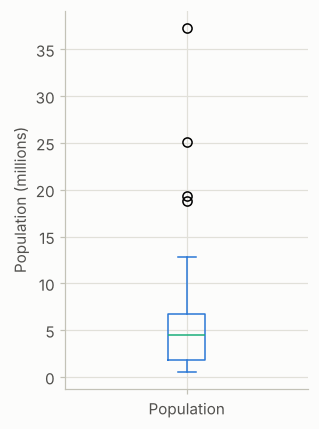

In [22]:
# BOOK CODE (Percentiles and Boxplots): boxplot of the population
# Pandas provides a number of basic exploratory plots; one of them are boxplots

ax = (state['Population']/1_000_000).plot.box(figsize=(3, 4))
ax.set_ylabel('Population (millions)')

plt.tight_layout()
plt.show()

In [23]:
# BOOK CODE (Frequency Table and Histograms): equal-width bins, Table 1.5
binnedPopulation = pd.cut(state['Population'], 10)
print(binnedPopulation.value_counts())

# Table 1.5
binnedPopulation.name = 'binnedPopulation'
df = pd.concat([state, binnedPopulation], axis=1)
df = df.sort_values(by='Population')

groups = []
for group, subset in df.groupby(by='binnedPopulation', observed=False):
    groups.append({
        'BinRange': group,
        'Count': len(subset),
        'States': ','.join(subset.Abbreviation)
    })
print(pd.DataFrame(groups))

Population
(526935.67, 4232659.0]      24
(4232659.0, 7901692.0]      14
(7901692.0, 11570725.0]      6
(11570725.0, 15239758.0]     2
(15239758.0, 18908791.0]     1
(18908791.0, 22577824.0]     1
(22577824.0, 26246857.0]     1
(33584923.0, 37253956.0]     1
(26246857.0, 29915890.0]     0
(29915890.0, 33584923.0]     0
Name: count, dtype: int64
                   BinRange  Count                                             States
0    (526935.67, 4232659.0]     24  WY,VT,ND,AK,SD,DE,MT,RI,NH,ME,HI,ID,NE,WV,NM,N...
1    (4232659.0, 7901692.0]     14          KY,LA,SC,AL,CO,MN,WI,MD,MO,TN,AZ,IN,MA,WA
2   (7901692.0, 11570725.0]      6                                  VA,NJ,NC,GA,MI,OH
3  (11570725.0, 15239758.0]      2                                              PA,IL
4  (15239758.0, 18908791.0]      1                                                 FL
5  (18908791.0, 22577824.0]      1                                                 NY
6  (22577824.0, 26246857.0]      1                 

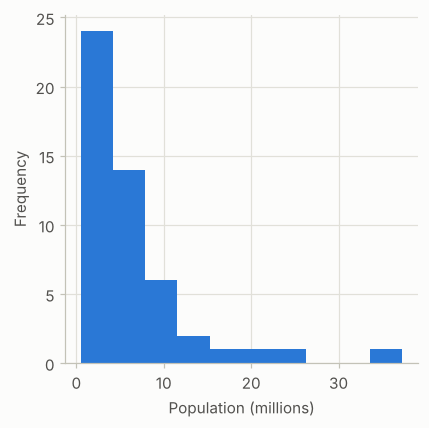

In [24]:
# BOOK CODE (Frequency Table and Histograms): histogram of the population
# Pandas also supports histograms for exploratory data analysis.

ax = (state['Population'] / 1_000_000).plot.hist(figsize=(4, 4))
ax.set_xlabel('Population (millions)')

plt.tight_layout()
plt.show()

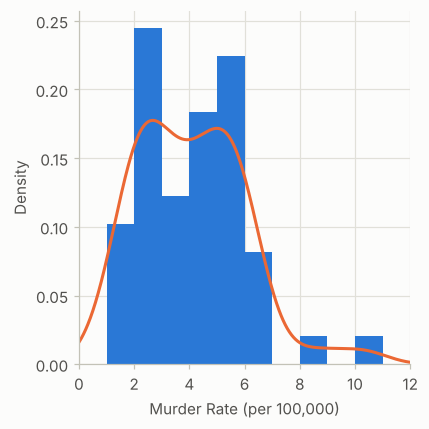

In [25]:
# BOOK CODE (Density Estimates): histogram and density of the murder rate
# Density is an alternative to histograms that can provide more insight into the distribution of the data points.
# Use the argument bw_method to control the smoothness of the density curve.

ax = state['Murder.Rate'].plot.hist(density=True, xlim=[0, 12],
                                    bins=range(1,12), figsize=(4, 4))
state['Murder.Rate'].plot.density(ax=ax)
ax.set_xlabel('Murder Rate (per 100,000)')

plt.tight_layout()
plt.show()

**Output analysis.**

* **Percentiles.** The 5th, 25th, 50th, 75th and 95th percentiles of the murder rate are 1.6, 2.425, 4.0, 5.55 and 6.51: half of the states are between 2.4 and 5.6, and between the 5th and 95th percentiles the distribution is roughly symmetric (the median is 2.4 above the 5th percentile and 2.5 below the 95th). The long upper tail lies beyond the 95th percentile: the largest rate is 10.3. The second table is the same result in the layout of the book's Table 1-4.
* **Boxplot of the population.** The median is about 4.4 million, the box runs from 1.8 to 6.7 million, the upper whisker ends near 12.8 million, and four states are drawn above it as outliers (California, Texas, New York, Florida; extra 5(b) lists them).
* **Frequency table.** `pd.cut` makes ten bins of equal width (3.67 million). 24 states are in the first bin, 14 in the second, 6 in the third, then 2, 1, 1, 1, two empty bins and California alone in the last. The bins are listed in order of frequency in the first output and in order of position in the second.
* **Histogram and density.** The histogram of the populations is strongly right-skewed. The density curve of the murder rates has two humps, near 2.5 and 5, and a long thin tail to the right (the states at 8.6 and 10.3). The histogram of the murder rates uses the bins `range(1, 12)` of the book's code, which start at 1, so the state with the lowest rate (0.9) is not counted: the bars cover 49 states, the density curve all 50.

### Extra experiments

**(a) Nine definitions of a percentile.** `numpy.percentile` implements the nine definitions of Hyndman and Fan through its `method` argument. The cell computes the five percentiles of the book's Table 1.4 with each of them for the 50 murder rates, and compares with the `pandas` default.

In [26]:
# EXTRA (a): the nine quantile definitions on the 50 murder rates
methods = {1: "inverted_cdf", 2: "averaged_inverted_cdf", 3: "closest_observation", 4: "interpolated_inverted_cdf", 5: "hazen",
           6: "weibull", 7: "linear", 8: "median_unbiased", 9: "normal_unbiased"}
levels = [5, 25, 50, 75, 95]
table = pd.DataFrame({f"type {t}: {m}": np.percentile(state["Murder.Rate"], levels, method=m) for t, m in methods.items()}, index=[f"{p}%" for p in levels]).T
print(table.round(3).to_string())
print("\npandas default (quantile):", state["Murder.Rate"].quantile([p / 100 for p in levels]).round(3).tolist())
print(f"largest disagreement between the nine definitions: {(table.max() - table.min()).round(3).to_dict()}")

                                    5%    25%  50%   75%    95%
type 1: inverted_cdf               1.6  2.400  4.0  5.60  6.600
type 2: averaged_inverted_cdf      1.6  2.400  4.0  5.60  6.600
type 3: closest_observation        1.6  2.400  4.0  5.60  6.600
type 4: interpolated_inverted_cdf  1.6  2.400  4.0  5.50  6.500
type 5: hazen                      1.6  2.400  4.0  5.60  6.600
type 6: weibull                    1.6  2.400  4.0  5.60  7.500
type 7: linear                     1.6  2.425  4.0  5.55  6.510
type 8: median_unbiased            1.6  2.400  4.0  5.60  6.900
type 9: normal_unbiased            1.6  2.400  4.0  5.60  6.825

pandas default (quantile): [1.6, 2.425, 4.0, 5.55, 6.51]
largest disagreement between the nine definitions: {'5%': 0.0, '25%': 0.025, '50%': 0.0, '75%': 0.1, '95%': 1.0}


**Analysis of extra (a).**

* The nine definitions agree at the 5th and the 50th percentiles (1.6 and 4.0) and are within 0.025 at the 25th (2.400 to 2.425). They differ by 0.1 at the 75th (5.5 to 5.6) and by 1.0 at the 95th (6.5 to 7.5).
* The 95th percentile is the extreme case because the upper tail has a gap: the largest values are 6.0, 6.1, 6.4, 6.6, 8.6 and 10.3. The default (type 7) puts the point at position 47.55, between 6.4 and 6.6, and returns 6.51; type 6 puts it at 48.45, between 6.6 and 8.6, and returns 7.5; types 1 to 3 all return 6.6 here.
* The lesson: percentiles near the ends of a small sample depend on a convention. With thousands of observations the nine definitions are indistinguishable, but with 50 they are not, and a report should say which one it used.

**(b) A boxplot by hand.** The cell computes the quartiles, the fences, the whisker ends and the flagged points of the state populations from the definitions, and compares them with the statistics that `matplotlib` draws.

In [27]:
# EXTRA (b): the five numbers and the fences of a boxplot, by hand and with matplotlib
from matplotlib.cbook import boxplot_stats

values = state["Population"].to_numpy(float) / 1e6
q1, med, q3 = np.percentile(values, [25, 50, 75])
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
inside = values[(values >= low_fence) & (values <= high_fence)]
flagged = state.loc[(values < low_fence) | (values > high_fence), ["State", "Population"]].sort_values("Population", ascending=False)
print(f"Q1 {q1:.3f}, median {med:.3f}, Q3 {q3:.3f}, IQR {iqr:.3f} (millions)")
print(f"fences {low_fence:.3f} and {high_fence:.3f}; whiskers end at {inside.min():.3f} and {inside.max():.3f}")
print("flagged as outliers:", ", ".join(f"{s} ({p / 1e6:.2f})" for s, p in zip(flagged["State"], flagged["Population"])))

stats_mpl = boxplot_stats(values)[0]
print(f"matplotlib: whiskers {stats_mpl['whislo']:.3f} and {stats_mpl['whishi']:.3f}, {len(stats_mpl['fliers'])} fliers -> same as by hand: "
      f"{np.isclose(stats_mpl['whislo'], inside.min()) and np.isclose(stats_mpl['whishi'], inside.max()) and len(stats_mpl['fliers']) == len(flagged)}")

rng = np.random.default_rng(1)
normal_sample = rng.normal(size=1_000_000)
a, b = np.percentile(normal_sample, [25, 75])
share = np.mean((normal_sample < a - 1.5 * (b - a)) | (normal_sample > b + 1.5 * (b - a)))
print(f"\nshare of a normal sample outside the fences: {share:.3%} (theory 0.7%); here {len(flagged)} of 50 states = {len(flagged) / 50:.0%}")

Q1 1.833, median 4.436, Q3 6.680, IQR 4.847 (millions)
fences -5.438 and 13.951; whiskers end at 0.564 and 12.831
flagged as outliers: California (37.25), Texas (25.15), New York (19.38), Florida (18.80)
matplotlib: whiskers 0.564 and 12.831, 4 fliers -> same as by hand: True

share of a normal sample outside the fences: 0.715% (theory 0.7%); here 4 of 50 states = 8%


**Analysis of extra (b).**

* The by-hand computation reproduces `matplotlib`: the quartiles are 1.833 and 6.680 million (IQR 4.847), the fences are $-5.438$ and 13.951, the whiskers end at the most extreme values inside them (0.564 and 12.831), and four states are flagged. The check `matplotlib` against by hand is `True`.
* For a normal sample the rule flags 0.715% of the values (theory 0.7%), which would be 0.36 states in 50. Here 4 of 50 (8%) are flagged, because the variable is right-skewed. The flagged states are real states, not errors: a boxplot marks values that are far from the bulk, and whether they are mistakes is a question the data cannot answer.

**(c) How many bins?** Three rules of thumb, plus `NumPy`'s automatic choice, are applied to the state populations. The figure compares the book's ten bins with a coarse histogram and with the Freedman–Diaconis rule.

                 rule  bin width (millions)  number of bins
              sturges                 5.241               7
                scott                 6.115               6
                   fd                 2.621              14
                 auto                 2.621              14
book: pd.cut(..., 10)                 3.669              10
width asked for by Scott's rule 6.424 -> 6 bins of width 6.115; by Freedman-Diaconis 2.632 -> 14 bins of width 2.621


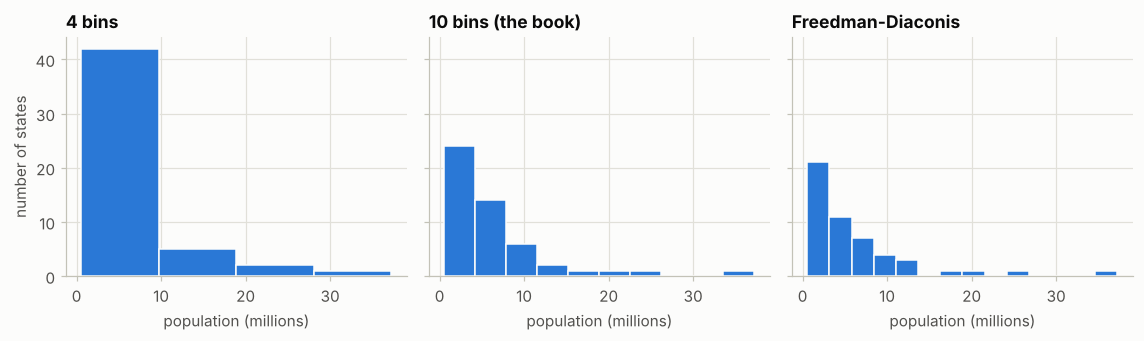

In [28]:
# EXTRA (c): rules for the number of bins, applied to the state populations
pop_millions = state["Population"].to_numpy(float) / 1e6
rows = []
for rule in ("sturges", "scott", "fd", "auto"):
    edges = np.histogram_bin_edges(pop_millions, bins=rule)
    rows.append({"rule": rule, "bin width (millions)": edges[1] - edges[0], "number of bins": len(edges) - 1})
rows.append({"rule": "book: pd.cut(..., 10)", "bin width (millions)": (pop_millions.max() - pop_millions.min()) / 10, "number of bins": 10})
print(pd.DataFrame(rows).round(3).to_string(index=False))
# the widths that the formulas ask for; NumPy then rounds the number of bins up, and stretches the bins so that they cover the range exactly
n_obs = len(pop_millions)
target_scott = (24 * np.sqrt(np.pi)) ** (1 / 3) * pop_millions.std(ddof=0) * n_obs ** (-1 / 3)
target_fd = 2 * (np.percentile(pop_millions, 75) - np.percentile(pop_millions, 25)) * n_obs ** (-1 / 3)
print(f"width asked for by Scott's rule {target_scott:.3f} -> {np.ceil(np.ptp(pop_millions) / target_scott):.0f} bins of width {np.ptp(pop_millions) / np.ceil(np.ptp(pop_millions) / target_scott):.3f}; "
      f"by Freedman-Diaconis {target_fd:.3f} -> {np.ceil(np.ptp(pop_millions) / target_fd):.0f} bins of width {np.ptp(pop_millions) / np.ceil(np.ptp(pop_millions) / target_fd):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)
for ax, bins, title in zip(axes, (4, 10, "fd"), ("4 bins", "10 bins (the book)", "Freedman-Diaconis")):
    ax.hist(pop_millions, bins=bins, color=PALETTE[0], edgecolor=SURFACE)
    ax.set_title(title)
    ax.set_xlabel("population (millions)")
axes[0].set_ylabel("number of states")
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* The rules disagree by more than a factor of two on this small, skewed sample: Sturges gives 7 bins (width 5.24 million), Scott 6 (width 6.12), Freedman-Diaconis 14 (width 2.62), and the book's choice of 10 bins has a width of 3.67. `numpy`'s `auto` picks the Freedman-Diaconis result here (14 bins).
* The rules ask for a width and `numpy` then rounds the number of bins up and stretches them to cover the range exactly. Scott's formula asks for 6.424 and gives 6 bins of 6.115; Freedman-Diaconis asks for 2.632 and gives 14 bins of 2.621.
* The figure shows what is at stake: with 4 bins 42 of the 50 states fall in the first bin and the shape is lost; with 10 or 14 bins the long right tail and the isolated large states are visible. The right-skew is the same under every choice; the amount of detail is not. A good habit is to try two or three widths before drawing a conclusion.

**(d) The bandwidth of a density estimate.** The density of the murder rates is estimated with four bandwidth factors: a small one, Scott's default $n^{-1/5}$ (what `pandas` uses), Silverman's $(3n/4)^{-1/5}$, and a large one. The cell also measures the probability mass that each estimate puts below zero, where no state can be.

standard deviation of the 50 rates 1.916; Scott's factor n^(-1/5) = 0.4573; gaussian_kde default factor = 0.4573


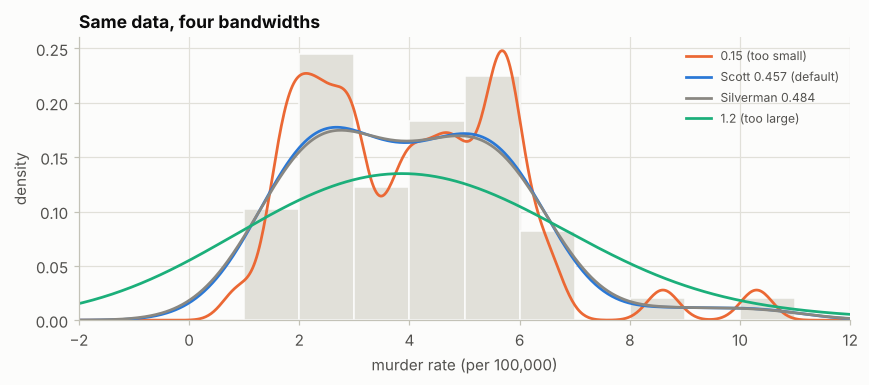

     bandwidth factor  bandwidth h = factor x sd  mass below zero  number of modes
     0.15 (too small)                     0.2874           0.0000                5
Scott 0.457 (default)                     0.8761           0.0069                2
      Silverman 0.484                     0.9280           0.0084                2
      1.2 (too large)                     2.2989           0.0813                1


In [29]:
# EXTRA (d): bandwidth of the kernel density estimate of the murder rate
from scipy.stats import gaussian_kde

n_states = len(rate)
scott, silverman = n_states ** (-1 / 5), (3 * n_states / 4) ** (-1 / 5)
factors = {"0.15 (too small)": 0.15, f"Scott {scott:.3f} (default)": scott, f"Silverman {silverman:.3f}": silverman, "1.2 (too large)": 1.2}
grid = np.linspace(-4, 14, 721)
print(f"standard deviation of the 50 rates {rate.std(ddof=1):.3f}; Scott's factor n^(-1/5) = {scott:.4f}; gaussian_kde default factor = {gaussian_kde(rate).factor:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(rate, bins=range(1, 12), density=True, color=GRID, edgecolor=SURFACE)
rows = []
for (label, factor), color in zip(factors.items(), [PALETTE[1], PALETTE[0], MUTED, PALETTE[2]]):
    kde = gaussian_kde(rate, bw_method=factor)
    density = kde(grid)
    ax.plot(grid, density, color=color, label=label, lw=1.8)
    rows.append({"bandwidth factor": label, "bandwidth h = factor x sd": factor * rate.std(ddof=1), "mass below zero": kde.integrate_box_1d(-np.inf, 0), "number of modes": int(np.sum((density[1:-1] > density[:-2]) & (density[1:-1] > density[2:])))})
ax.set_xlim(-2, 12)
ax.set_xlabel("murder rate (per 100,000)")
ax.set_ylabel("density")
ax.set_title("Same data, four bandwidths")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))

**Analysis of extra (d).**

* The default bandwidth factor of `gaussian_kde` is Scott's $n^{-1/5} = 0.4573$ (the check in the first line is exact); Silverman's factor is 0.484 and gives an almost identical curve, 2 modes in both cases.
* A factor of 0.15 is too small: the curve has 5 modes and reacts to individual states (the bump at 10.3 is one state). A factor of 1.2 is too large: one mode, the two humps merge, and 8.1% of the probability lies below zero, where no murder rate can be; the default puts 0.7% there.
* The histogram behind the curves has the book's bins `range(1, 12)`, which leave out the lowest rate (0.9), so its bars cover 49 states.
* The bandwidth plays the role of the bin width of the histogram: it decides what is read as structure and what as noise. The mass below zero is a reminder that a kernel estimate does not know the bounds of a variable.

**(e) Equal width against equal count.** `pd.cut` makes bins of equal width, as the book does; `pd.qcut` makes bins with (about) equal numbers of observations. The cell compares the two for the populations of the states.

In [30]:
# EXTRA (e): equal-width bins (cut) and equal-count bins (qcut) of the population
equal_width = pd.cut(state["Population"] / 1e6, 10)
equal_count = pd.qcut(state["Population"] / 1e6, 10)
print(pd.DataFrame({"cut: bin": equal_width.value_counts(sort=False).index.astype(str), "states": equal_width.value_counts(sort=False).to_numpy(),
                    "qcut: bin": equal_count.value_counts(sort=False).index.astype(str), "states ": equal_count.value_counts(sort=False).to_numpy()}).to_string(index=False))
print(f"width of the widest qcut bin: {max(i.right - i.left for i in equal_count.cat.categories):.2f} million; of the narrowest: {min(i.right - i.left for i in equal_count.cat.categories):.2f} million")

        cut: bin  states        qcut: bin  states 
  (0.527, 4.233]      24    (0.563, 0.89]        5
  (4.233, 7.902]      14    (0.89, 1.354]        5
 (7.902, 11.571]       6   (1.354, 2.508]        5
 (11.571, 15.24]       2   (2.508, 3.015]        5
 (15.24, 18.909]       1   (3.015, 4.436]        5
(18.909, 22.578]       1   (4.436, 5.457]        5
(22.578, 26.247]       1    (5.457, 6.42]        5
(26.247, 29.916]       0    (6.42, 8.941]        5
(29.916, 33.585]       0  (8.941, 12.715]        5
(33.585, 37.254]       1 (12.715, 37.254]        5
width of the widest qcut bin: 24.54 million; of the narrowest: 0.33 million


**Analysis of extra (e).**

* `cut` gives equal widths and very unequal counts: 24 states in the first bin, 14 in the second, none in two bins. `qcut` gives equal counts (5 states in each of the 10 bins) and very unequal widths: the narrowest bin is 0.33 million wide and the widest 24.54 million.
* Equal-width bins show the shape of the distribution (a histogram); equal-count bins show where the quantiles are (they are the deciles) and cannot show a shape, since a wide bin with the same count looks as important as a narrow one. A table with equal-count bins is useful for describing a variable, a table with equal-width bins for plotting it.

---
## 6. Exploring binary and categorical data

*Book section: "Exploring Binary and Categorical Data" (mode, expected value, probability).*

### Summary

* For binary and categorical data the basic summaries are the **proportions** (or percentages) of each category, shown in a **frequency table** or, graphically, in a **bar chart**: the categories on one axis and their frequency on the other. The book advises bar charts rather than pie charts.
* The **mode** is the most frequent category (or value).
* The **expected value** is the mean of a categorical variable whose categories can be given numeric values: each value is multiplied by the probability of its category and the products are added. The book illustrates it with a small business example in which every possible payment has a probability of being made; the expected value of a binary 0/1 variable is the probability of the 1.
* **Probability** is the proportion of times that an event would happen in many repetitions; the book introduces it here informally (probability comes back later in the book).
* **Example.** The table of the causes of delay at Dallas/Fort Worth airport gives the delays by cause: *inbound* (42.4%), *air traffic control* (30.4%), *carrier* (23.0%), *weather* (4.0%) and *security* (0.1%).
* Terms of this section: *mode*, *expected value*, *bar charts*, *pie charts*.

### Theory

**The distribution of a categorical variable.** A categorical variable with categories $k = 1, \dots, K$ is described by its probabilities $p_k = P(X = k)$, which sum to one; the proportions in a sample are estimates of them (the sample frequencies maximize the likelihood of a multinomial model). The **mode** is $\arg\max_k p_k$. A *binary* variable is a Bernoulli variable: with $P(X = 1) = p$ its mean (expected value) is $p$ and its variance $p(1-p)$, so the sample mean of 0/1 values is a proportion, and its standard error is $\sqrt{p(1-p)/n}$.

**Expected value.** For a variable with numeric values $x_k$, $E[X] = \sum_k x_k p_k$; it is the long-run average, and the sample mean estimates it. It is the "center of mass" of the distribution, so it may be a value that cannot be observed (an average of 2.4 children).

**Concentration of a categorical distribution.** The **Shannon entropy** (Shannon, 1948) $H = -\sum_k p_k \log_2 p_k$ measures how spread out the probabilities are: it is 0 when one category has everything and $\log_2 K$ when all are equally likely. Its exponential, $2^H$, is an *effective number of categories*: a variable with 5 categories of which one has 99% of the mass behaves like a variable with about 1.1 categories.

**Why bars and not slices.** Cleveland and McGill (1984) ranked how accurately people read quantities from different graphical encodings: position along a common scale is read most accurately, length less so, and angle and area (what a pie chart uses) less accurately still. A bar chart sorted by frequency (a **Pareto chart** when a cumulative line is added) lets the eye compare lengths against a common baseline, and shows how few categories carry most of the weight. An *ordinal* variable should keep its natural order on the axis instead of being sorted by frequency.

### Book code

The book's code of the section: the percentages of the causes of delay (Table 1-6) and their bar chart.

In [31]:
# BOOK CODE (Exploring Binary and Categorical Data): causes of delay at Dallas/Fort Worth, Table 1-6
dfw = pd.read_csv(AIRPORT_DELAYS_CSV)
print(100 * dfw / dfw.values.sum())

     Carrier        ATC   Weather  Security    Inbound
0  23.022989  30.400781  4.025214  0.122937  42.428079


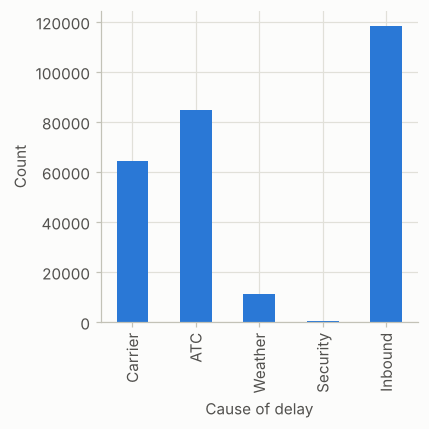

In [32]:
# BOOK CODE (Exploring Binary and Categorical Data): bar chart of the causes of delay
# Pandas also supports bar charts for displaying a single categorical variable.

ax = dfw.transpose().plot.bar(figsize=(4, 4), legend=False)
ax.set_xlabel('Cause of delay')
ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

**Output analysis.**

* **Table 1-6.** The causes of delay at Dallas/Fort Worth are: inbound 42.4%, air traffic control 30.4%, carrier 23.0%, weather 4.0% and security 0.1%. Inbound delays and air traffic control together are almost three quarters of all delays.
* **Bar chart.** The bars follow the order of the columns of the table (carrier, ATC, weather, security, inbound), not the order of size, so the eye has to look for the largest. The vertical axis is labelled *Count* although the values are not whole numbers (extra 2(d)). Extra 6(b) sorts the bars.

### Extra experiments

**(a) Mode, expected value and entropy.** For the causes of delay and for the loan grades (451,000 loans), the cell reports the mode, the proportions, the entropy and the effective number of categories. For the grades, which are ordinal, it also computes the expected grade under the assumption that the grades A to G are the numbers 1 to 7 (an assumption of equal steps that the data do not justify).

In [33]:
# EXTRA (a): proportions, mode, entropy and expected value of two categorical variables
def describe_categorical(counts):
    p = counts / counts.sum()
    entropy = -(p[p > 0] * np.log2(p[p > 0])).sum()
    return p, entropy


delay_counts = dfw.iloc[0].astype(float)
grade_counts = lc_loans["grade"].value_counts().sort_index()
rows = []
for label, counts in (("cause of delay at DFW", delay_counts), ("loan grade", grade_counts)):
    p, entropy = describe_categorical(counts)
    rows.append({"variable": label, "categories": len(counts), "mode": p.idxmax(), "share of the mode": p.max(), "entropy (bits)": entropy,
                 "maximum log2(K)": np.log2(len(counts)), "effective number of categories": 2 ** entropy})
print(pd.DataFrame(rows).round(3).to_string(index=False))

p_grade = grade_counts / grade_counts.sum()
print("\nloan grades:", {g: f"{v:.3f}" for g, v in p_grade.items()})
print(f"expected grade with A=1, ..., G=7: {(p_grade.to_numpy() * np.arange(1, 8)).sum():.3f}; median grade: {p_grade.cumsum().ge(0.5).idxmax()}")

status = lc_loans["status"].value_counts(normalize=True)
print("loan status:", {k: f"{v:.3f}" for k, v in status.items()})
print(f"expected value of the indicator 'charged off' (= its proportion): {(lc_loans['status'] == 'Charged Off').mean():.4f}")

             variable  categories    mode  share of the mode  entropy (bits)  maximum log2(K)  effective number of categories
cause of delay at DFW           5 Inbound              0.424           1.733            2.322                           3.325
           loan grade           7       B              0.294           2.364            2.807                           5.147

loan grades: {'A': '0.161', 'B': '0.294', 'C': '0.268', 'D': '0.165', 'E': '0.077', 'F': '0.029', 'G': '0.007'}
expected grade with A=1, ..., G=7: 2.819; median grade: C
loan status: {'Current': '0.712', 'Fully Paid': '0.216', 'Charged Off': '0.050', 'Late': '0.022'}
expected value of the indicator 'charged off' (= its proportion): 0.0503


**Analysis of extra (a).**

* **Mode and concentration.** The mode of the causes of delay is *inbound* with 42.4% of the delays; the mode of the loan grades is B with 29.4%. The entropy of the causes is 1.733 bits out of a maximum of 2.322, an effective number of 3.3 categories out of 5; for the grades it is 2.364 bits out of 2.807, 5.1 effective categories out of 7. The grades are more evenly spread than the delays.
* **Expected value of an ordinal variable.** With the numbers A = 1, ..., G = 7 the expected grade is 2.82, between B and C, closer to C, and the median grade is C (the grades A and B hold 45.4% of the loans, A to C 72.2%). The expected value needs the assumption that the steps between grades are equal; the median needs only the order.
* **Binary variable.** The expected value of the indicator "charged off" is 0.0503, the proportion of charged-off loans: 5.0% of the 450,961 loans. The other statuses are current 71.2%, fully paid 21.6% and late 2.2%.

**(b) A Pareto chart, and an ordinal axis.** The causes of delay are sorted by frequency with the cumulative share (a Pareto chart), next to the loan grades in their natural order. The first chart answers "which causes matter most"; for the second, sorting by frequency would destroy the order of the grades.

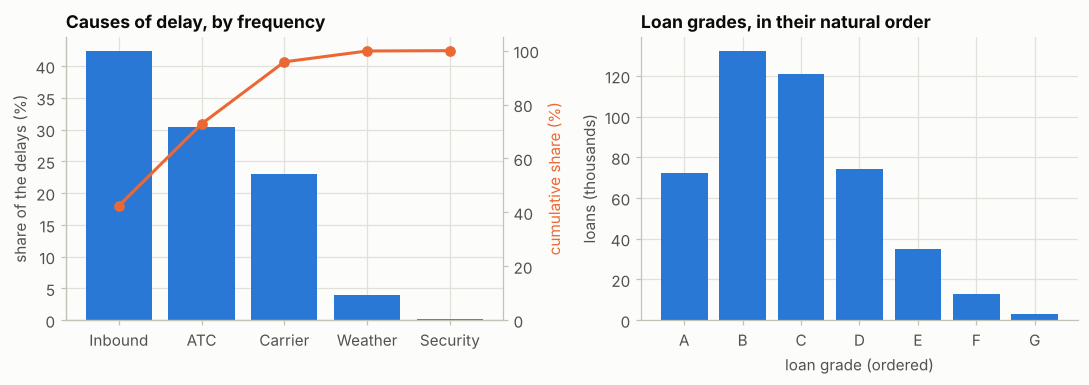

cumulative shares: {'Inbound': 0.424, 'ATC': 0.728, 'Carrier': 0.959, 'Weather': 0.999, 'Security': 1.0}


In [34]:
# EXTRA (b): a Pareto chart for a nominal variable, a natural order for an ordinal one
sorted_delays = (delay_counts / delay_counts.sum()).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(sorted_delays.index, sorted_delays * 100, color=PALETTE[0])
twin = axes[0].twinx()
twin.plot(sorted_delays.index, sorted_delays.cumsum() * 100, color=PALETTE[1], marker="o")
twin.set_ylim(0, 105)
twin.spines["right"].set_visible(True)
twin.grid(False)
axes[0].set_ylabel("share of the delays (%)")
twin.set_ylabel("cumulative share (%)", color=PALETTE[1])
axes[0].set_title("Causes of delay, by frequency")
axes[1].bar(grade_counts.index, grade_counts / 1000, color=PALETTE[0])
axes[1].set_xlabel("loan grade (ordered)")
axes[1].set_ylabel("loans (thousands)")
axes[1].set_title("Loan grades, in their natural order")
plt.tight_layout()
plt.show()
print("cumulative shares:", sorted_delays.cumsum().round(3).to_dict())

**Analysis of extra (b).**

* **Pareto chart.** The cumulative line shows that inbound and ATC delays make 72.8% of the total, and the first three causes 95.9%; weather and security together add 4.1%. The sorted bars make the ranking readable at once, which the book's chart (in the order of the columns) does not.
* **Ordinal variable.** The loan grades are drawn in their natural order, A to G. Sorting them by frequency would put B, C, D, A, E, F, G and destroy the ordering that gives the variable its meaning; the picture then shows a distribution with a mode at B and a thin right tail of risky grades.

---
## 7. Correlation

*Book section: "Correlation" (correlation coefficient, correlation matrix, scatterplots).*

### Summary

* Exploratory analysis often asks whether variables move together. Two variables are **positively correlated** if high values of one go with high values of the other, **negatively correlated** if high goes with low.
* The **correlation coefficient** (Pearson's) puts this on a scale from $-1$ (a perfect negative linear relation) to $+1$ (a perfect positive one), with $0$ meaning no linear relation. It is computed from the standardized values of the two variables, so it does not depend on their units.
* A **correlation matrix** lists the coefficients of all pairs of variables; with many variables a **heatmap** (or an ellipse plot, which also works in greyscale) makes it readable. The book builds one for the daily price changes of the exchange-traded funds (ETFs) of the S&P 500 data, where the funds that track the market move together.
* Like the mean and the standard deviation, the coefficient is **sensitive to outliers**. **Robust** alternatives exist, based on the ranks of the data (Spearman's $\rho$ and Kendall's $\tau$); this notebook compares them with Pearson's coefficient in extras 7(a) and 7(b).
* A **scatterplot** shows two variables point by point and is the plot to look at *before* trusting a correlation: the coefficient says nothing about the shape of the relation.
* **Example.** The daily changes of the stock prices of AT&T (T) and Verizon (VZ), two telecommunications companies, are positively correlated (about 0.68).
* Terms of this section: *correlation coefficient*, *correlation matrix*, *scatterplot*.

### Theory

**Covariance and the correlation coefficient.** For paired observations $(x_i, y_i)$ the *sample covariance* is $s_{xy} = \frac{1}{n-1}\sum (x_i - \bar{x})(y_i - \bar{y})$; it has the units of $x$ times those of $y$ and so cannot be compared across pairs. Dividing by the two standard deviations gives Pearson's coefficient
$$r = \frac{s_{xy}}{s_x s_y} = \frac{1}{n-1} \sum_{i=1}^{n} \left(\frac{x_i - \bar{x}}{s_x}\right)\left(\frac{y_i - \bar{y}}{s_y}\right),$$
the average product of the standardized values. By the Cauchy–Schwarz inequality $|r| \le 1$, with $|r| = 1$ exactly when the points lie on a straight line. The coefficient is symmetric in $x$ and $y$, and unchanged by changes of unit and of origin ($x \to a x + b$ with $a > 0$). Its square, $r^2$, is the share of the variance of $y$ explained by the straight-line fit on $x$ (Chapter 4).

**What it does not measure.** $r$ measures **linear** association. $y = x^2$ on symmetric data has $r = 0$ although $y$ is a function of $x$; two relations with the same $r$ can look completely different (Anscombe, 1973, extra 7(c)). And correlation is not causation: a third variable may drive both, or the direction may be the opposite of what one assumed.

**Rank correlations.** *Spearman's* $\rho$ is Pearson's coefficient computed on the ranks of the data; it measures how monotone the relation is and is not affected by outliers beyond their rank. *Kendall's* $\tau$ counts pairs: $\tau = (C - D) / \binom{n}{2}$ with $C$ concordant pairs (the two variables order the pair alike) and $D$ discordant ones. For a monotone relation the three agree in sign, and for bivariate normal data they are linked ($\rho_S \approx \tfrac{6}{\pi}\arcsin(r/2)$ and $\tau = \tfrac{2}{\pi}\arcsin(r)$), with $|\tau| < |\rho_S| < |r|$ for moderate correlation.

**Uncertainty of $r$.** The sampling distribution of $r$ is skewed when $|\rho|$ is large; Fisher's transformation (Fisher, 1921) $z = \operatorname{artanh}(r) = \tfrac12 \ln\frac{1+r}{1-r}$ is approximately normal with standard error $1/\sqrt{n-3}$, which gives the confidence interval $\tanh(z \pm z_{1-\alpha/2}/\sqrt{n-3})$. For testing $\rho = 0$ under normality, $t = r\sqrt{(n-2)/(1-r^2)}$ has a $t$ distribution with $n-2$ degrees of freedom. With a large $n$ a tiny $r$ is "significant", so the size of $r$, not its p-value, is what to interpret.

**Spurious correlation.** Two series that trend or wander, such as prices, can have a large correlation with no relation at all. Yule (1926) called these *nonsense correlations*, and Granger and Newbold (1974) showed that regressions of independent random walks on each other routinely look significant. The remedy is to correlate **changes** (returns, differences) rather than levels, which is what the S&P data of the book contain; extra 7(e) measures the effect.

### Book code

The book's code of the section: the telecommunications stocks (Table 1-7), the ETF data, the heatmap, the ellipse plot (the heatmap does not show the direction of the correlation in greyscale) and two scatterplots.

In [35]:
# BOOK CODE (Correlation): read the data sets of the stocks
# First read the required datasets

sp500_sym = pd.read_csv(SP500_SECTORS_CSV)
sp500_px = pd.read_csv(SP500_DATA_CSV, index_col=0)

# Table 1-7
# Determine telecommunications symbols
telecomSymbols = sp500_sym[sp500_sym['sector'] == 'telecommunications_services']['symbol']

# Filter data for dates July 2012 through June 2015
telecom = sp500_px.loc[sp500_px.index >= '2012-07-01', telecomSymbols]
telecom.corr()

,T,CTL,FTR,VZ,LVLT
T,1.000000,0.474683,0.327767,0.677612,0.278626
CTL,0.474683,1.000000,0.419757,0.416604,0.286665
FTR,0.327767,0.419757,1.000000,0.287386,0.260068
VZ,0.677612,0.416604,0.287386,1.000000,0.242199
LVLT,0.278626,0.286665,0.260068,0.242199,1.000000


In [36]:
# BOOK CODE (Correlation): the telecom data (in the official script `telecom.corr()` is computed without being displayed)
print(telecom)

                   T       CTL       FTR        VZ      LVLT
2012-07-02  0.422496  0.140847  0.070879  0.554180 -0.519998
2012-07-03 -0.177448  0.066280  0.070879 -0.025976 -0.049999
2012-07-05 -0.160548 -0.132563  0.055128 -0.051956 -0.180000
2012-07-06  0.342205  0.132563  0.007875  0.140106 -0.359999
2012-07-09  0.136883  0.124279 -0.023626  0.253943  0.180000
...              ...       ...       ...       ...       ...
2015-06-25  0.049342 -1.600000 -0.040000 -0.187790 -0.330002
2015-06-26 -0.256586  0.039999 -0.070000  0.029650 -0.739998
2015-06-29 -0.098685 -0.559999 -0.060000 -0.504063 -1.360000
2015-06-30 -0.503298 -0.420000 -0.070000 -0.523829  0.199997
2015-07-01 -0.019737  0.080000 -0.050000  0.355811  0.139999

[754 rows x 5 columns]


In [37]:
# BOOK CODE (Correlation): exchange-traded funds
# Next we focus on funds traded on major exchanges (sector == 'etf').

etfs = sp500_px.loc[sp500_px.index > '2012-07-01',
                    sp500_sym[sp500_sym['sector'] == 'etf']['symbol']]
print(etfs.head())

                 XLI       QQQ       SPY       DIA       GLD    VXX       USO       IWM       XLE       XLY       XLU       XLB       XTL       XLV       XLP       XLF       XLK
2012-07-02 -0.376098  0.096313  0.028223 -0.242796  0.419998 -10.40  0.000000  0.534641  0.028186  0.095759  0.098311 -0.093713  0.019076 -0.009529  0.313499  0.018999  0.075668
2012-07-03  0.376099  0.481576  0.874936  0.728405  0.490006  -3.52  0.250000  0.926067  0.995942  0.000000 -0.044686  0.337373  0.000000  0.000000  0.129087  0.104492  0.236462
2012-07-05  0.150440  0.096313 -0.103487  0.149420  0.239991   6.56 -0.070000 -0.171848 -0.460387  0.306431 -0.151938  0.103086  0.019072 -0.142955 -0.073766 -0.142490  0.066211
2012-07-06 -0.141040 -0.491201  0.018819 -0.205449 -0.519989  -8.80 -0.180000 -0.229128  0.206706  0.153214  0.080437  0.018744 -0.429213 -0.095304  0.119865  0.066495 -0.227003
2012-07-09  0.244465 -0.048160 -0.056445 -0.168094  0.429992  -0.48  0.459999 -0.190939 -0.234892 -0.201098 -0

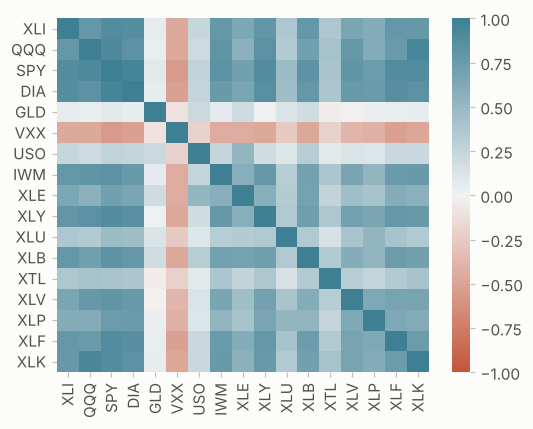

In [38]:
# BOOK CODE (Correlation): heatmap of the correlation matrix of the ETFs
# Due to the large number of columns in this table, looking at the correlation matrix is cumbersome and it's more
# convenient to plot the correlation as a heatmap. The seaborn package provides a convenient implementation for heatmaps.

fig, ax = plt.subplots(figsize=(5, 4))
ax = sns.heatmap(etfs.corr(), vmin=-1, vmax=1,
                 cmap=sns.diverging_palette(20, 220, as_cmap=True),
                 ax=ax)

plt.tight_layout()
plt.show()

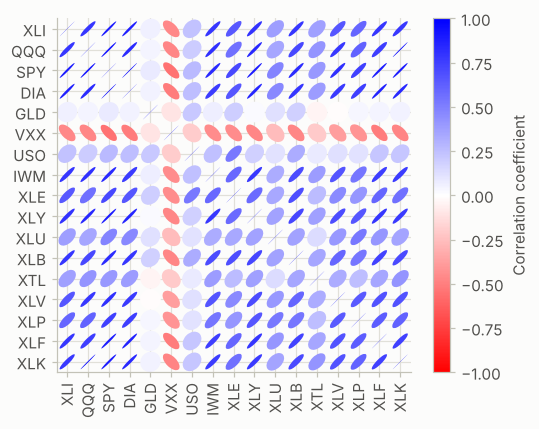

In [39]:
# BOOK CODE (Correlation): ellipse plot of the correlation matrix
# The above heatmap works when you have color. For the greyscale images, as used in the book, we need to visualize
# the direction as well. The following code shows the strength of the correlation using ellipses.

from matplotlib.collections import EllipseCollection
from matplotlib.colors import Normalize

def plot_corr_ellipses(data, figsize=None, **kwargs):
    """ https://stackoverflow.com/a/34558488 """
    M = np.array(data)
    if not M.ndim == 2:
        raise ValueError('data must be a 2D array')
    fig, ax = plt.subplots(1, 1, figsize=figsize, subplot_kw={'aspect':'equal'})
    ax.set_xlim(-0.5, M.shape[1] - 0.5)
    ax.set_ylim(-0.5, M.shape[0] - 0.5)
    ax.invert_yaxis()

    # xy locations of each ellipse center
    xy = np.indices(M.shape)[::-1].reshape(2, -1).T

    # set the relative sizes of the major/minor axes according to the strength of
    # the positive/negative correlation
    w = np.ones_like(M).ravel() + 0.01
    h = 1 - np.abs(M).ravel() - 0.01
    a = 45 * np.sign(M).ravel()

    ec = EllipseCollection(widths=w, heights=h, angles=a, units='x', offsets=xy,
                           norm=Normalize(vmin=-1, vmax=1),
                           transOffset=ax.transData, array=M.ravel(), **kwargs)
    ax.add_collection(ec)

    # if data is a DataFrame, use the row/column names as tick labels
    if isinstance(data, pd.DataFrame):
        ax.set_xticks(np.arange(M.shape[1]))
        ax.set_xticklabels(data.columns, rotation=90)
        ax.set_yticks(np.arange(M.shape[0]))
        ax.set_yticklabels(data.index)

    return ec, ax

m, ax = plot_corr_ellipses(etfs.corr(), figsize=(5, 4), cmap='bwr_r')
cb = plt.colorbar(m, ax=ax)
cb.set_label('Correlation coefficient')

plt.tight_layout()
plt.show()

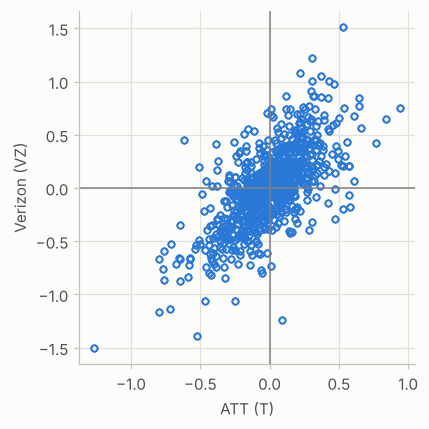

Line2D(_child2)


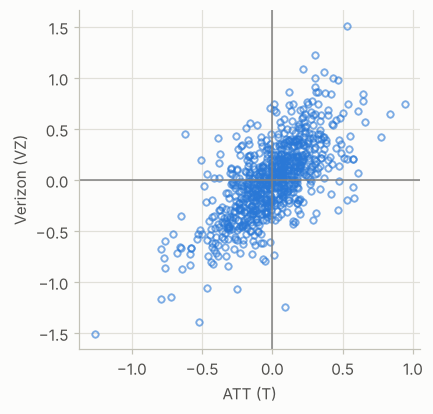

In [40]:
# BOOK CODE (Scatterplots): AT&T against Verizon
# Simple scatterplots are supported by pandas. Specifying the marker as $\u25EF$ uses an open circle for each point.

ax = telecom.plot.scatter(x='T', y='VZ', figsize=(4, 4), marker='$\u25EF$')
ax.set_xlabel('ATT (T)')
ax.set_ylabel('Verizon (VZ)')
ax.axhline(0, color='grey', lw=1)
ax.axvline(0, color='grey', lw=1)

plt.tight_layout()
plt.show()

ax = telecom.plot.scatter(x='T', y='VZ', figsize=(4, 4), marker='$\u25EF$', alpha=0.5)
ax.set_xlabel('ATT (T)')
ax.set_ylabel('Verizon (VZ)')
ax.axhline(0, color='grey', lw=1)
print(ax.axvline(0, color='grey', lw=1))

**Output analysis.**

* **Telecom stocks.** AT&T (`T`) and Verizon (`VZ`) have the highest correlation of the daily price changes (0.678); the other pairs are lower (AT&T and CenturyLink `CTL` 0.475, AT&T and Frontier `FTR` 0.328), and Level 3 (`LVLT`) is the least related to the others (0.24 to 0.29). All coefficients are positive: the stocks share the movements of the market. The printed `telecom` table shows the data behind them: 754 daily changes from 2012-07-02 to 2015-07-01.
* **ETFs.** The 17 funds are in dollars of daily price change, so their scales differ widely (the daily standard deviations run from 0.14 dollars for `XLF` to 2.54 for `VXX`, see extra 7(a)), which is one reason why a scale-free coefficient is convenient.
* **Heatmap.** The broad-market and sector funds form a block of positive correlations; `VXX`, a fund that follows market volatility, has a row and a column of negative values (red); gold (`GLD`) and oil (`USO`) are only weakly related to the rest.
* **Ellipse plot.** The same matrix in a form that also works in greyscale: a thin ellipse leaning to the right is a strong positive correlation, leaning to the left a negative one, and a circle no linear relation.
* **Scatterplots.** AT&T against Verizon is a cloud that leans to the upper right around the origin, in line with $r = 0.68$. In the second plot transparency makes the dense center visible. The line `Line2D(_child2)` is the printed representation of the vertical line, which the official code prints; it carries no information.

### Extra experiments

**(a) The formula by hand, and three coefficients.** Pearson's $r$ of AT&T and Verizon is computed from the definition (standardized products), compared with `pandas`, and set beside Spearman's $\rho$ and Kendall's $\tau$. The cell also ranks the pairs of ETFs by correlation.

In [41]:
# EXTRA (a): Pearson by hand, Spearman, Kendall, and the most extreme pairs of ETFs
from scipy import stats

x, y = telecom["T"].to_numpy(), telecom["VZ"].to_numpy()
n_days = len(x)
z_x, z_y = (x - x.mean()) / x.std(ddof=1), (y - y.mean()) / y.std(ddof=1)
r_hand = (z_x * z_y).sum() / (n_days - 1)
rho, tau = stats.spearmanr(x, y)[0], stats.kendalltau(x, y)[0]
print(f"{n_days} days; Pearson by hand {r_hand:.4f}, by pandas {telecom['T'].corr(telecom['VZ']):.4f}, by numpy {np.corrcoef(x, y)[0, 1]:.4f}")
print(f"Spearman {rho:.4f}, Kendall {tau:.4f}; normal-theory links: Spearman ~ {6 / np.pi * np.arcsin(r_hand / 2):.4f}, Kendall ~ {2 / np.pi * np.arcsin(r_hand):.4f}")
print(f"covariance {np.cov(x, y)[0, 1]:.5f} = r * sx * sy = {r_hand * x.std(ddof=1) * y.std(ddof=1):.5f}; r squared {r_hand ** 2:.3f}")
print(f"units do not matter: r in cents instead of dollars {np.corrcoef(100 * x, 100 * y)[0, 1]:.4f}")

pairs = etfs.corr().where(np.triu(np.ones((17, 17), dtype=bool), 1)).stack().dropna().sort_values()
print("\nmost negative pairs of ETFs:", [(a, b, round(v, 3)) for (a, b), v in pairs.head(3).items()])
print("most positive pairs of ETFs:", [(a, b, round(v, 3)) for (a, b), v in pairs.tail(3).items()])
daily_sd = etfs.std()
print(f"daily standard deviation of the ETFs, in dollars: from {daily_sd.min():.2f} ({daily_sd.idxmin()}) to {daily_sd.max():.2f} ({daily_sd.idxmax()})")
print(f"median correlation among the 136 pairs: {pairs.median():.3f}; share of pairs with r above 0.5: {(pairs > 0.5).mean():.0%}")

754 days; Pearson by hand 0.6776, by pandas 0.6776, by numpy 0.6776
Spearman 0.6650, Kendall 0.4902; normal-theory links: Spearman ~ 0.6601, Kendall ~ 0.4740
covariance 0.06587 = r * sx * sy = 0.06587; r squared 0.459
units do not matter: r in cents instead of dollars 0.6776

most negative pairs of ETFs: [('SPY', 'VXX', -0.547), ('VXX', 'XLF', -0.514), ('DIA', 'VXX', -0.511)]
most positive pairs of ETFs: [('QQQ', 'SPY', 0.909), ('QQQ', 'XLK', 0.945), ('SPY', 'DIA', 0.954)]
daily standard deviation of the ETFs, in dollars: from 0.14 (XLF) to 2.54 (VXX)
median correlation among the 136 pairs: 0.459; share of pairs with r above 0.5: 49%


**Analysis of extra (a).**

* **The formula.** Pearson's $r$ computed by hand as the mean of the products of the standardized values is 0.6776, the same as `pandas` and `numpy`. The covariance equals $r\,s_x s_y$ (0.06587), $r^2 = 0.459$ (about 46% of the variance of one stock's daily change is linearly shared with the other), and the coefficient does not change if the prices are in cents.
* **Rank coefficients.** Spearman's $\rho$ is 0.665 and Kendall's $\tau$ 0.490, below $r$ as expected, and close to the values that bivariate normality would give (0.660 and 0.474), which is consistent with that model, though it does not prove it.
* **ETFs.** The most negatively correlated pairs all involve `VXX` (with `SPY` $-0.547$, with `XLF` $-0.514$, with `DIA` $-0.511$); the most positive are `SPY` and `DIA` (0.954), `QQQ` and `XLK` (0.945) and `QQQ` and `SPY` (0.909). The median correlation of the 136 pairs is 0.459 and 49% of the pairs are above 0.5: funds that track the stock market move together.

**(b) One outlier.** A single wrong observation is added to the 754 days: first a point that goes against the relation (AT&T up by 8 dollars, Verizon down by 8), then a point that goes with it. The cell reports the three coefficients each time.

In [42]:
# EXTRA (b): the effect of one extreme point on Pearson, Spearman and Kendall
def three_coefficients(a, b):
    return {"Pearson r": np.corrcoef(a, b)[0, 1], "Spearman rho": stats.spearmanr(a, b)[0], "Kendall tau": stats.kendalltau(a, b)[0]}


rows = {"the 754 days": three_coefficients(x, y),
        "plus one point (8, -8), against the relation": three_coefficients(np.append(x, 8), np.append(y, -8)),
        "plus one point (8, 8), with the relation": three_coefficients(np.append(x, 8), np.append(y, 8))}
print(pd.DataFrame(rows).T.round(3).to_string())

                                              Pearson r  Spearman rho  Kendall tau
the 754 days                                      0.678         0.665        0.490
plus one point (8, -8), against the relation     -0.103         0.658        0.486
plus one point (8, 8), with the relation          0.812         0.666        0.492


**Analysis of extra (b).**

* One wrong day out of 755 changes Pearson's $r$ from 0.678 to $-0.103$ when the point goes against the relation, and to 0.812 when it goes with it: a single observation can erase a correlation or inflate it.
* The rank coefficients hardly notice: Spearman stays between 0.658 and 0.666 and Kendall between 0.486 and 0.492, because an extreme point has only the influence of one rank. When outliers are possible and the relation is monotone, report a rank correlation next to $r$.

**(c) Anscombe's quartet.** Anscombe (1973) built four small data sets with the same means, variances, correlation and regression line, and completely different shapes. The cell computes the summary statistics of each and draws them.

data set  mean x  mean y  variance x  variance y  correlation  slope  intercept  Spearman
       I     9.0   7.501        11.0       4.127        0.816    0.5      3.000     0.818
      II     9.0   7.501        11.0       4.128        0.816    0.5      3.001     0.691
     III     9.0   7.500        11.0       4.123        0.816    0.5      3.002     0.991
      IV     9.0   7.501        11.0       4.123        0.817    0.5      3.002     0.500


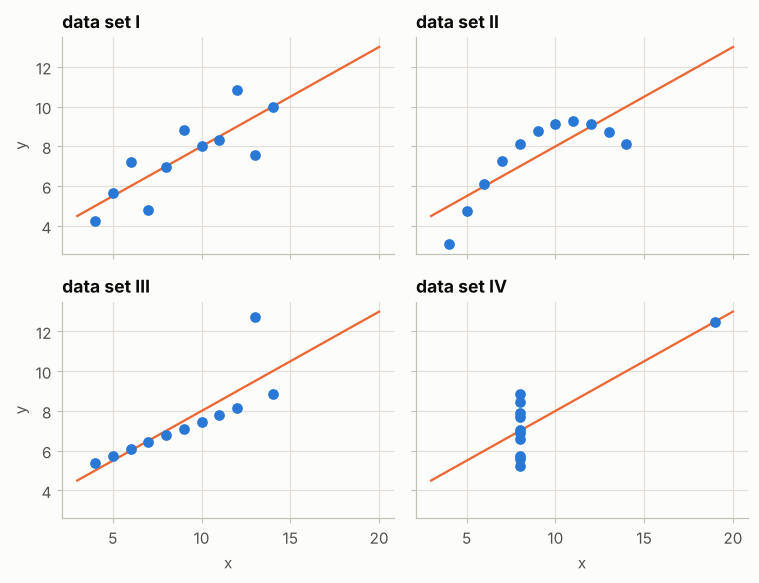

In [43]:
# EXTRA (c): Anscombe's quartet (data of Anscombe, 1973)
anscombe_x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
quartet = {
    "I": (anscombe_x, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II": (anscombe_x, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (anscombe_x, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV": ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
rows = []
for name, (qx, qy) in quartet.items():
    qx, qy = np.array(qx, float), np.array(qy, float)
    slope, intercept = np.polyfit(qx, qy, 1)
    rows.append({"data set": name, "mean x": qx.mean(), "mean y": qy.mean(), "variance x": qx.var(ddof=1), "variance y": qy.var(ddof=1),
                 "correlation": np.corrcoef(qx, qy)[0, 1], "slope": slope, "intercept": intercept, "Spearman": stats.spearmanr(qx, qy)[0]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(7, 5.4), sharex=True, sharey=True)
for ax, (name, (qx, qy)) in zip(axes.ravel(), quartet.items()):
    ax.scatter(qx, qy, color=PALETTE[0], zorder=3)
    line = np.array([3, 20])
    ax.plot(line, np.polyval(np.polyfit(qx, qy, 1), line), color=PALETTE[1], lw=1.5)
    ax.set_title(f"data set {name}")
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

**Analysis of extra (c).**

* The four data sets have the same mean of $x$ (9.0), mean of $y$ (7.50), variance of $x$ (11.0), variance of $y$ (4.13), correlation (0.816) and regression line ($y = 3.0 + 0.5x$).
* The pictures are completely different: I is a noisy straight line, II a clean curve, III a perfect line with one outlier, and IV has all but one $x$ equal, so the whole fit rests on a single point at $x = 19$.
* Spearman's coefficient separates them to some extent (0.818, 0.691, 0.991, 0.500), but no summary replaces the plot. Look at the scatterplot before reporting a correlation.

**(d) How certain is a correlation?** The confidence interval of $r$ for AT&T and Verizon is computed from Fisher's transformation, checked against `scipy`, and the test of $\rho = 0$ is computed from the $t$ statistic. The last lines show how the interval narrows with the number of days.

In [44]:
# EXTRA (d): Fisher's confidence interval for r, the t test of rho = 0, and the effect of n
z = np.arctanh(r_hand)
half = stats.norm.ppf(0.975) / np.sqrt(n_days - 3)
low, high = np.tanh(z - half), np.tanh(z + half)
print(f"r = {r_hand:.4f}; Fisher z = {z:.4f}, standard error {1 / np.sqrt(n_days - 3):.4f}; 95% interval ({low:.4f}, {high:.4f})")
ci = stats.pearsonr(x, y).confidence_interval()
print(f"scipy.stats.pearsonr interval ({ci.low:.4f}, {ci.high:.4f})")
t_stat = r_hand * np.sqrt((n_days - 2) / (1 - r_hand ** 2))
print(f"t statistic for rho = 0: {t_stat:.2f} with {n_days - 2} degrees of freedom; p-value {2 * stats.t.sf(abs(t_stat), n_days - 2):.2e}")

rows = []
for m_days in (10, 30, 100, 300, 754):
    sub_r = np.corrcoef(x[:m_days], y[:m_days])[0, 1]
    half_m = stats.norm.ppf(0.975) / np.sqrt(m_days - 3)
    rows.append({"days": m_days, "r": sub_r, "lower": np.tanh(np.arctanh(sub_r) - half_m), "upper": np.tanh(np.arctanh(sub_r) + half_m)})
print()
print(pd.DataFrame(rows).round(3).to_string(index=False))

r = 0.6776; Fisher z = 0.8247, standard error 0.0365; 95% interval (0.6370, 0.7144)
scipy.stats.pearsonr interval (0.6370, 0.7144)
t statistic for rho = 0: 25.27 with 752 degrees of freedom; p-value 1.85e-102

 days     r  lower  upper
   10 0.861  0.506  0.967
   30 0.725  0.494  0.861
  100 0.719  0.608  0.802
  300 0.649  0.578  0.710
  754 0.678  0.637  0.714


**Analysis of extra (d).**

* The Fisher interval for the correlation of AT&T and Verizon is (0.637, 0.714), identical to that of `scipy`; the standard error of $z$ is $1/\sqrt{751} = 0.0365$. The $t$ statistic for $\rho = 0$ is 25.3 on 752 degrees of freedom and the p-value is about $10^{-102}$: with 754 days there is overwhelming evidence that the correlation is positive, and the interval is more informative than the p-value. Both rest on independent, roughly normal pairs; daily price changes have heavy tails and a changing volatility, so the p-value is approximate.
* The last table shows how the interval narrows with the number of days: with the first 10 days $r = 0.861$ and the interval (0.51, 0.97) is useless; with 100 days (0.61, 0.80); with 754 days (0.64, 0.71). The width shrinks about as $1/\sqrt{n}$. A correlation from 10 observations says very little, and the small-sample value (0.861) is far from the full-sample one.

**(e) Spurious correlation of random walks.** 2,000 pairs of **independent** random walks of 250 steps are generated (their increments are independent standard normal numbers). The cell correlates each pair in *levels* (the walks themselves, like prices) and in *changes* (their first differences, like the daily changes of the S&P data).

                         levels (the walks)  changes (the steps)
standard deviation of r               0.489                0.063
share with |r| > 0.5                  0.393                0.000
share with |r| > 0.8                  0.072                0.000
largest |r|                           0.958                0.234
for independent variables the standard deviation of r is about 1/sqrt(n) = 0.063 (n = 250)


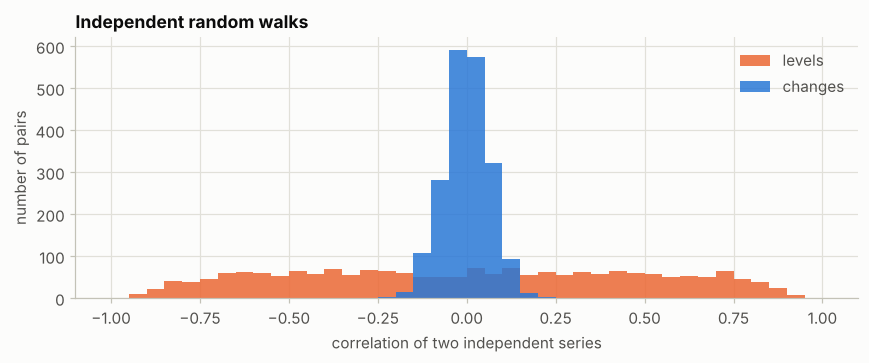

In [45]:
# EXTRA (e): independent random walks are often "strongly correlated" in levels, never in changes
rng = np.random.default_rng(2024)
steps_a, steps_b = rng.normal(size=(2000, 250)), rng.normal(size=(2000, 250))
walks_a, walks_b = steps_a.cumsum(axis=1), steps_b.cumsum(axis=1)


def row_correlation(a, b):
    a, b = a - a.mean(1, keepdims=True), b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))


levels, changes = row_correlation(walks_a, walks_b), row_correlation(steps_a, steps_b)
print(pd.DataFrame({"levels (the walks)": [levels.std(), np.mean(np.abs(levels) > 0.5), np.mean(np.abs(levels) > 0.8), np.abs(levels).max()],
                    "changes (the steps)": [changes.std(), np.mean(np.abs(changes) > 0.5), np.mean(np.abs(changes) > 0.8), np.abs(changes).max()]},
                   index=["standard deviation of r", "share with |r| > 0.5", "share with |r| > 0.8", "largest |r|"]).round(3).to_string())
print(f"for independent variables the standard deviation of r is about 1/sqrt(n) = {1 / np.sqrt(250):.3f} (n = 250)")

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(-1, 1, 41)
ax.hist(levels, bins=bins, color=PALETTE[1], alpha=0.85, label="levels")
ax.hist(changes, bins=bins, color=PALETTE[0], alpha=0.85, label="changes")
ax.set_xlabel("correlation of two independent series")
ax.set_ylabel("number of pairs")
ax.set_title("Independent random walks")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis of extra (e).**

* For independent series, the correlation of the **changes** behaves as theory says: a standard deviation of 0.063 (theory $1/\sqrt{250} = 0.063$), no pair above 0.5 in absolute value, the largest 0.234.
* The correlation of the **levels** (the random walks themselves) is a different animal: the standard deviation is 0.489, 39.3% of the independent pairs have $|r| > 0.5$, 7.2% have $|r| > 0.8$, and the largest is 0.958. The histogram is spread over the whole interval and is almost flat, while the one for the changes is a narrow peak at zero.
* The reason is that a random walk wanders: successive values are strongly dependent, so 250 values carry the information of far fewer independent observations, and the usual standard error does not apply. This is the nonsense correlation of Yule (1926). Correlating the daily changes, as the data of the book do, avoids the problem.

---
## 8. Exploring two or more variables

*Book section: "Exploring Two or More Variables" (hexagonal binning and contours, two categorical variables, categorical and numeric data, visualizing multiple variables).*

### Summary

* The estimates of the earlier sections are **univariate**; correlation is **bivariate** (a pair of variables); a **multivariate** analysis considers three or more at once. The tools depend on the types of the variables.
* **Numeric against numeric, with many records.** A scatterplot of hundreds of thousands of points turns into a solid blob. **Hexagonal binning** divides the plane into hexagons and colors each by the number of records in it; a **contour plot** (a two-dimensional density estimate) draws lines of equal density, like a topographic map. The book uses the tax-assessed values and the floor areas of 432,693 houses in King County.
* **Two categorical variables.** A **contingency table** counts the records for every combination of the categories; the percentages by row show how the distribution of one variable changes with the other. The book uses the grade and the status of lending-club loans.
* **Categorical against numeric.** A **boxplot** (or a **violin plot**, which adds a mirrored density curve) of the numeric variable for each category compares distributions. The book compares the daily percentage of delayed flights of six airlines.
* **More variables.** The plot can be **conditioned** on a variable: a different panel for each value (facets, also called *trellis* or *small-multiple* plots) lets the eye compare the relation between two variables across the groups. The book conditions the hexbin plot of area against value on four ZIP codes.
* Terms of this section: *contingency table*, *hexagonal binning*, *contour plot*, *violin plot*.

### Theory

**Overplotting.** A scatterplot draws one mark per record. When the number of records exceeds the number of distinguishable positions, marks overlap and the plot shows only the extent of the cloud, not where the data are dense. Remedies are transparency (`alpha`), smaller marks, a random subsample, or **binning** the plane and coloring each bin by its count (the two-dimensional histogram; hexagons are preferred to squares because a hexagon is closer to a circle and all its neighbors are at the same distance) or by a smooth **two-dimensional kernel density estimate**, the bivariate version of the density plot of section 5 with a bandwidth for each axis.

**Contingency tables and independence.** For two categorical variables with $r$ and $c$ categories and $N$ records, the table of counts $O_{ij}$ has *marginals* (row and column totals). Two variables are **independent** if $P(i, j) = P(i)P(j)$; then the expected count in a cell is $E_{ij} = R_i C_j / N$. The row percentages $O_{ij}/R_i$ are *conditional* distributions: if the variables are independent, every row shows the same distribution (the marginal one). Pearson's statistic $\chi^2 = \sum_{ij} (O_{ij} - E_{ij})^2 / E_{ij}$ measures the gap, and under independence follows approximately a chi-square distribution with $(r-1)(c-1)$ degrees of freedom (Chapter 3 returns to it). Because $\chi^2$ grows in proportion to $N$, an *effect size* is needed: Cramér's $V$ (Cramér, 1946) $= \sqrt{\chi^2 / (N \min(r-1, c-1))}$ lies between 0 and 1 and does not grow with the sample size. The standardized *Pearson residuals* $(O_{ij} - E_{ij})/\sqrt{E_{ij}}$ show which cells depart from independence.

**Categorical against numeric.** A boxplot summarizes each group by five numbers and flags outliers (section 5); a violin plot draws a mirrored kernel density estimate and therefore shows features that the boxplot cannot, such as two modes or a long tail (it does not know the limits of the data, so its smoothing can spill over them). Both compare the *shape* as well as the location of the groups.

**Conditioning and Simpson's paradox.** A relation between two variables may change, or even reverse, when the data are split by a third variable. **Simpson's paradox** is the extreme case: a trend that appears in the aggregate is reversed in every subgroup, because the groups differ in size and in their baseline levels. Conditioning the plot on the suspected third variable (facets, also called trellis displays or small multiples) is the exploratory way to find out whether the pooled relation describes any of the groups, and the regression with an interaction (Chapter 4) is the confirmatory way.

### Book code

The book's code of the section: the King County tax data and its filter, the hexagonal binning and the contour plot, the contingency tables of the loans (counts and percentages), the boxplot and the violin plot of the airline delays, and the conditioned hexbin plot. The contour plot draws a random subsample without a seed in the book's code; the cell sets the seed of NumPy's generator first (`NOT IN THE BOOK`) so that the figure does not change from run to run.

In [46]:
# BOOK CODE (Exploring Two or More Variables): the tax data of King County
# Load the kc_tax dataset and filter based on a variety of criteria

kc_tax = pd.read_csv(KC_TAX_CSV)
kc_tax0 = kc_tax.loc[(kc_tax.TaxAssessedValue < 750000) &
                     (kc_tax.SqFtTotLiving > 100) &
                     (kc_tax.SqFtTotLiving < 3500), :]
print(kc_tax0.shape)

(432693, 3)


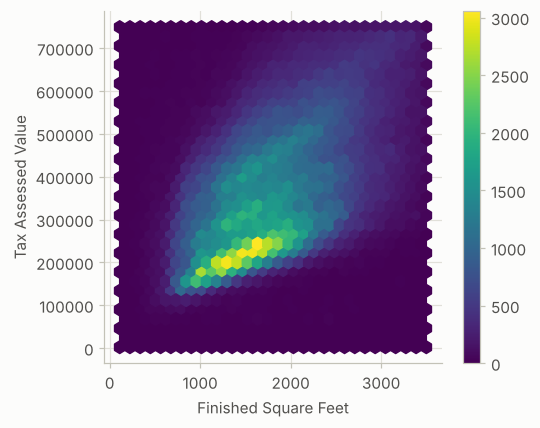

In [47]:
# BOOK CODE (Hexagonal binning and Contours): hexbin plot
# If the number of data points gets large, scatter plots will no longer be meaningful. Here methods that visualize
# densities are more useful. The hexbin method for pandas data frames is one powerful approach.

ax = kc_tax0.plot.hexbin(x='SqFtTotLiving', y='TaxAssessedValue',
                         gridsize=30, sharex=False, figsize=(5, 4))
ax.set_xlabel('Finished Square Feet')
ax.set_ylabel('Tax Assessed Value')

plt.tight_layout()
plt.show()

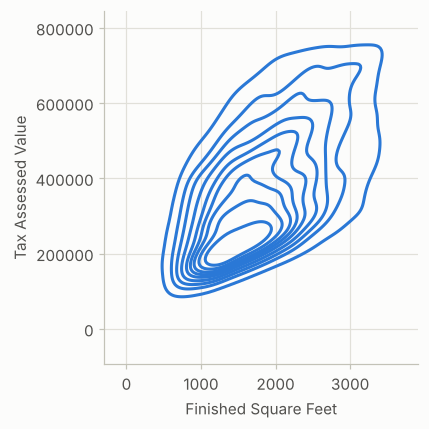

In [48]:
# BOOK CODE (Hexagonal binning and Contours): contour plot of a 2D kernel density estimate
# The seaborn kdeplot is a two-dimensional extension of the density plot. The calculation of the 2D-density for the
# full dataset takes several minutes. It is sufficient to create the visualization with a smaller sample of the dataset.
# With 10,000 data points, creating the graph takes only seconds. While some details may be lost, the overall shape is preserved.
np.random.seed(2024)  # NOT IN THE BOOK: the book's sample() has no seed

fig, ax = plt.subplots(figsize=(4, 4))
sns.kdeplot(data=kc_tax0.sample(10000), x='SqFtTotLiving', y='TaxAssessedValue', ax=ax)
ax.set_xlabel('Finished Square Feet')
ax.set_ylabel('Tax Assessed Value')

plt.tight_layout()
plt.show()

In [49]:
# BOOK CODE (Two Categorical Variables): the loans, Table 1-8(1)
# Load the lc_loans dataset

lc_loans = pd.read_csv(LC_LOANS_CSV)

# Table 1-8(1)
crosstab = lc_loans.pivot_table(index='grade', columns='status',
                                aggfunc=lambda x: len(x), margins=True)
print(crosstab)

status  Charged Off  Current  Fully Paid  Late     All
grade                                                 
A              1562    50051       20408   469   72490
B              5302    93852       31160  2056  132370
C              6023    88928       23147  2777  120875
D              5007    53281       13681  2308   74277
E              2842    24639        5949  1374   34804
F              1526     8444        2328   606   12904
G               409     1990         643   199    3241
All           22671   321185       97316  9789  450961


In [50]:
# BOOK CODE (Two Categorical Variables): the loans, Table 1-8(2), percentages by row
# Table 1-8(2)
df = crosstab.copy().loc['A':'G',:].astype(float)
df.loc[:,'Charged Off':'Late'] = df.loc[:,'Charged Off':'Late'].div(df['All'], axis=0)
df['All'] = df['All'] / sum(df['All'])
perc_crosstab = df
print(perc_crosstab)

status  Charged Off   Current  Fully Paid      Late       All
grade                                                        
A          0.021548  0.690454    0.281528  0.006470  0.160746
B          0.040054  0.709013    0.235401  0.015532  0.293529
C          0.049828  0.735702    0.191495  0.022974  0.268039
D          0.067410  0.717328    0.184189  0.031073  0.164708
E          0.081657  0.707936    0.170929  0.039478  0.077177
F          0.118258  0.654371    0.180409  0.046962  0.028614
G          0.126196  0.614008    0.198396  0.061401  0.007187


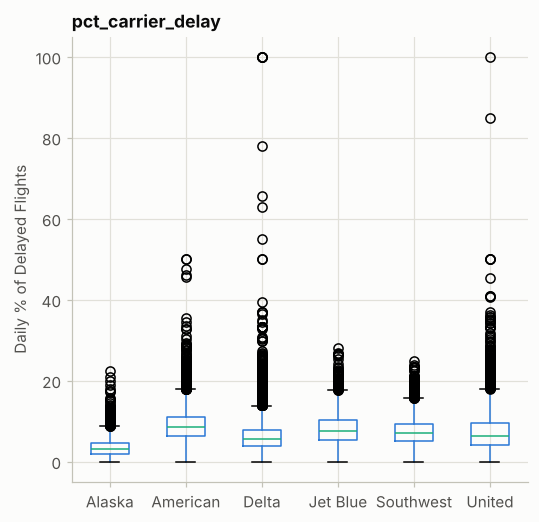

In [51]:
# BOOK CODE (Categorical and Numeric Data): boxplots of the delays by airline
# Pandas boxplots of a column can be grouped by a different column.

airline_stats = pd.read_csv(AIRLINE_STATS_CSV)
airline_stats.head()
ax = airline_stats.boxplot(by='airline', column='pct_carrier_delay',
                           figsize=(5, 5))
ax.set_xlabel('')
ax.set_ylabel('Daily % of Delayed Flights')
plt.suptitle('')

plt.tight_layout()
plt.show()

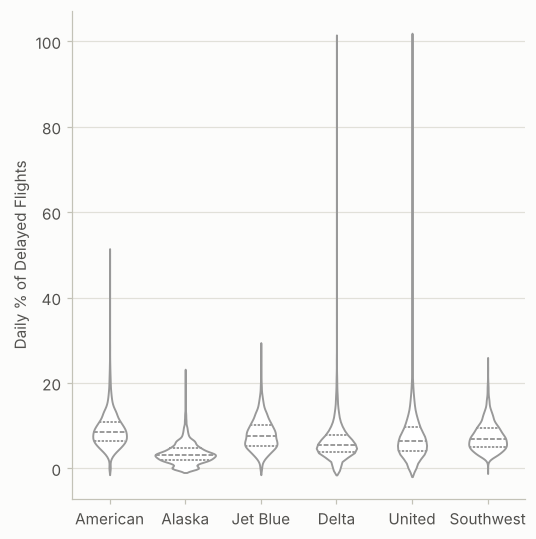

In [52]:
# BOOK CODE (Categorical and Numeric Data): violin plot of the delays by airline
# Pandas also supports a variation of boxplots called violinplot.

fig, ax = plt.subplots(figsize=(5, 5))
sns.violinplot(data=airline_stats, x='airline', y='pct_carrier_delay',
               ax=ax, inner='quartile', color='white')
ax.set_xlabel('')
ax.set_ylabel('Daily % of Delayed Flights')

plt.tight_layout()
plt.show()

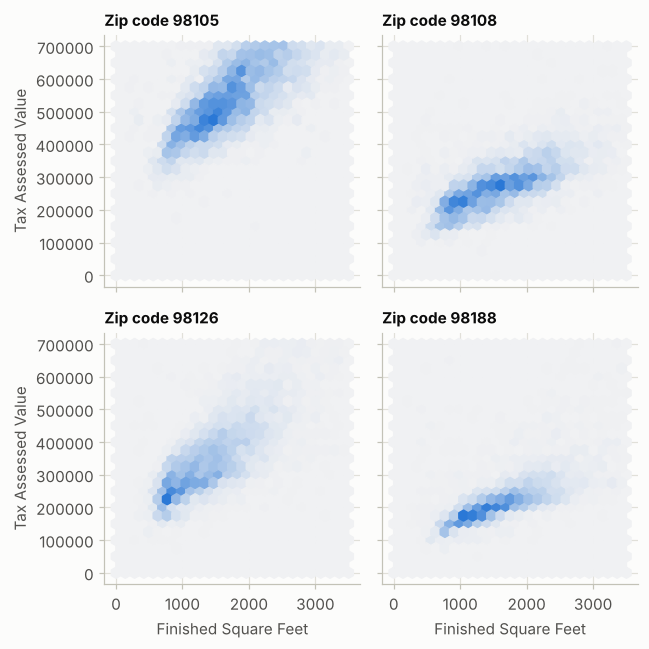

In [53]:
# BOOK CODE (Visualizing Multiple Variables): the hexbin plot conditioned on the ZIP code

zip_codes = [98188, 98105, 98108, 98126]
kc_tax_zip = kc_tax0.loc[kc_tax0.ZipCode.isin(zip_codes),:]
kc_tax_zip

def hexbin(x, y, color, **kwargs):
    cmap = sns.light_palette(color, as_cmap=True)
    plt.hexbin(x, y, gridsize=25, cmap=cmap, **kwargs)

g = sns.FacetGrid(kc_tax_zip, col='ZipCode', col_wrap=2)
g.map(hexbin, 'SqFtTotLiving', 'TaxAssessedValue',
      extent=[0, 3500, 0, 700000])
g.set_axis_labels('Finished Square Feet', 'Tax Assessed Value')
g.set_titles('Zip code {col_name:.0f}')

plt.tight_layout()
plt.show()

**Output analysis.**

* **The filtered tax data.** 432,693 of the 498,249 records remain after the filter (assessed value below 750,000 and area between 100 and 3,500 square feet). The filter is a choice of the book to concentrate on typical houses; it also makes the sharp upper and right edges of the plots, which are not features of the data.
* **Hexagonal binning.** The houses form a ridge that rises from the lower left (1,000 to 2,000 square feet, 150,000 to 300,000 dollars) to the upper right, the density falls quickly away from it, and the lower edge of the cloud is sharper than the upper one. The scatterplot of this many points would be a solid block (extra 8(f)).
* **Contour plot.** The two-dimensional density of 10,000 randomly chosen records draws nested lines around the same ridge, with the peak at about 1,500 square feet. The cell of this notebook fixes the seed of the random sample; the sample itself is the book's choice, to keep the computation short.
* **Contingency table of the loans.** 450,961 loans; the most numerous grades are B (132,370) and C (120,875) and 321,185 (71.2%) are *current*. The row percentages are conditional distributions: the share of *charged off* rises from 2.2% (grade A) to 12.6% (G) and the share of *late* from 0.6% to 6.1%; the share of *fully paid* falls from 28.2% (A) to 17.1% (E) and is 19.8% for G. Within each grade the share of current loans is between 61% and 74%.
* **Boxplot and violin plot.** The median of the carrier delay (percent of flights) is lowest for Alaska and highest for American; Delta and United show the longest tails, up to 100%. The violin plot adds the shape: a single main mode for each airline, a thin long tail for Delta and United, and a density that extends below 0 and above 100%, where no value can be, because the smoothing does not know the limits.
* **Conditioning on the ZIP code.** For houses of the same size the value differs strongly between ZIP codes: 98105 has the highest values and 98188 the lowest, with 98108 and 98126 in between. The slopes differ too (steepest for 98126 and 98105, flattest for 98108 and 98188), but most of the difference between the ZIP codes is in the level. Extra 8(i) measures both.

### Extra experiments

**(f) Overplotting.** The 432,693 houses of the filtered tax data are drawn three ways: a plain scatterplot (a solid blob), a random subsample of 2,000 points with transparency, and the hexagonal binning. The cell also counts how many records fall in each cell of a $30 \times 30$ grid.

432,693 records with both variables; 0 of the filtered rows have no value and are not drawn
30 x 30 grid: 872 of 900 cells occupied; busiest cell 3,671 records, median occupied cell 219
the busiest 10% of the occupied cells hold 41% of the records


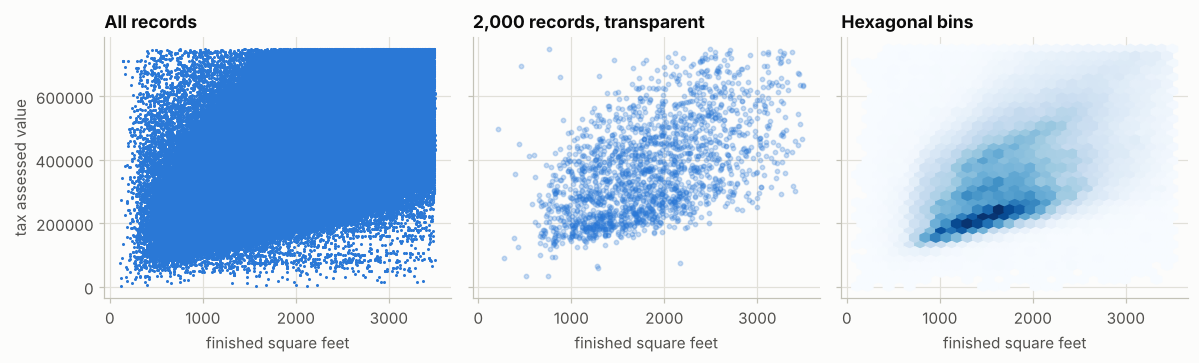

In [54]:
# EXTRA (f): overplotting, in numbers and in pictures
usable = kc_tax0.dropna(subset=["SqFtTotLiving", "TaxAssessedValue"])
counts, _, _ = np.histogram2d(usable["SqFtTotLiving"], usable["TaxAssessedValue"], bins=30)
occupied = counts[counts > 0]
print(f"{len(usable):,} records with both variables; {len(kc_tax0) - len(usable):,} of the filtered rows have no value and are not drawn")
print(f"30 x 30 grid: {len(occupied)} of {counts.size} cells occupied; busiest cell {int(counts.max()):,} records, median occupied cell {int(np.median(occupied)):,}")
print(f"the busiest 10% of the occupied cells hold {np.sort(occupied)[::-1][:max(1, len(occupied) // 10)].sum() / counts.sum():.0%} of the records")

sample = usable.sample(2000, random_state=2024)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
axes[0].scatter(usable["SqFtTotLiving"], usable["TaxAssessedValue"], s=1, color=PALETTE[0], rasterized=True)
axes[0].set_title("All records")
axes[1].scatter(sample["SqFtTotLiving"], sample["TaxAssessedValue"], s=8, color=PALETTE[0], alpha=0.25)
axes[1].set_title("2,000 records, transparent")
axes[2].hexbin(usable["SqFtTotLiving"], usable["TaxAssessedValue"], gridsize=30, cmap="Blues", mincnt=1)
axes[2].set_title("Hexagonal bins")
for ax in axes:
    ax.set_xlabel("finished square feet")
axes[0].set_ylabel("tax assessed value")
plt.tight_layout()
plt.show()

**Analysis of extra (f).**

* All 432,693 filtered records have both values (a comparison with a missing value is false, so the filter of the book has already removed them). They fall in 872 of the 900 cells of a $30 \times 30$ grid, the busiest cell holds 3,671 records and the median occupied cell 219, and the busiest 10% of the occupied cells hold 41% of the records: the data are very unevenly dense.
* The plain scatterplot of all the records is a solid block in the middle, so the density is invisible; the 2,000-point transparent subsample shows the dense center and the upward trend but has little detail at the edges; the hexagonal bins show the ridge and its direction. The choice of display decides whether the density structure is seen at all.

**(g) Is the grade of a loan related to its status?** The contingency table of the loans is tested for independence with the chi-square statistic, and the effect size (Cramér's $V$) and the Pearson residuals tell how strong the relation is and where it comes from.

In [55]:
# EXTRA (g): chi-square test of independence, Cramer's V and Pearson residuals for grade by status
from scipy.stats import chi2_contingency

table = pd.crosstab(lc_loans["grade"], lc_loans["status"])
chi2, p_value, dof, expected = chi2_contingency(table)
N = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (N * (min(table.shape) - 1)))
print(f"N = {N:,}; chi-square {chi2:,.0f} with {dof} degrees of freedom; p-value {p_value:.3g}; Cramer's V {cramers_v:.3f}")

expected = pd.DataFrame(expected, index=table.index, columns=table.columns)
residuals = (table - expected) / np.sqrt(expected)
print("\nPearson residuals ((observed - expected) / sqrt(expected))")
print(residuals.round(1).to_string())
print(f"\nlargest residual: {residuals.stack().abs().idxmax()} = {residuals.stack()[residuals.stack().abs().idxmax()]:.1f}")

small = pd.crosstab(lc_loans["grade"].iloc[::100], lc_loans["status"].iloc[::100])
chi2_small, p_small, _, _ = chi2_contingency(small)
print(f"\nthe same data thinned to every 100th loan (N = {small.to_numpy().sum():,}): chi-square {chi2_small:,.0f}, p-value {p_small:.3g}, "
      f"Cramer's V {np.sqrt(chi2_small / (small.to_numpy().sum() * (min(small.shape) - 1))):.3f}")

N = 450,961; chi-square 9,594 with 18 degrees of freedom; p-value 0; Cramer's V 0.084

Pearson residuals ((observed - expected) / sqrt(expected))
status  Charged Off  Current  Fully Paid  Late
grade                                         
A             -34.5     -6.9        38.1 -27.8
B             -16.6     -1.4        15.4 -15.2
C              -0.7      9.7       -18.2   3.0
D              20.8      1.6       -18.5  17.3
E              26.1     -0.9       -18.0  22.5
F              34.4     -7.8        -8.7  19.5
G              19.3     -6.6        -2.1  15.3

largest residual: ('A', 'Fully Paid') = 38.1

the same data thinned to every 100th loan (N = 4,510): chi-square 88, p-value 2.7e-11, Cramer's V 0.081


**Analysis of extra (g).**

* **The test.** $\chi^2 = 9{,}594$ with 18 degrees of freedom; the p-value is so small that it underflows to 0 in double precision. The grade and the status of a loan are not independent.
* **The effect size.** Cramér's $V$ is 0.084, which is small: the association between grade and status is weak, and most of the loans of every grade are current.
* **Where the dependence comes from.** The Pearson residuals follow a clear pattern: grade A has far fewer charged-off ($-34.5$) and late ($-27.8$) loans and far more fully paid ($+38.1$) than independence predicts, and the grades D to G the opposite for charged off and late (up to $+34.4$ for grade F). The residuals of grade G are smaller largely because that grade has few loans (3,241).
* **Sample size.** Thinning the data to every 100th loan (N = 4,510) gives $\chi^2 = 88$, a p-value of $2.7 \times 10^{-11}$ and the *same* effect size (0.081 against 0.084). The statistic shrinks in proportion to $N$, the effect size does not: with a large table every dependence is significant, so interpret $V$ and the residuals.
* **A caution.** The status is a snapshot: 71% of the loans are current, so their final outcome is not known and the table does not give the default rate of a grade.

**(h) Boxplot or violin?** For each airline the cell lists the median, the mean, the IQR, the skewness and the number of days flagged by the boxplot rule, for the daily share of flights delayed by the carrier.

In [56]:
# EXTRA (h): the numbers behind the boxplot and the violin plot of the airlines
def airline_summary(values):
    q1, med, q3 = np.percentile(values, [25, 50, 75])
    flagged = np.sum((values > q3 + 1.5 * (q3 - q1)) | (values < q1 - 1.5 * (q3 - q1)))
    return pd.Series({"days": len(values), "median": med, "mean": values.mean(), "IQR": q3 - q1, "skewness": stats.skew(values),
                      "days flagged": flagged, "share flagged": flagged / len(values)})


delays = airline_stats.dropna(subset=["pct_carrier_delay"])
summary = delays.groupby("airline")["pct_carrier_delay"].apply(lambda s: airline_summary(s.to_numpy())).unstack()
summary["days"] = summary["days"].astype(int)
summary["days flagged"] = summary["days flagged"].astype(int)
print(summary.round(3).sort_values("median").to_string())
print(f"\nall carriers together: median {delays['pct_carrier_delay'].median():.3f}, mean {delays['pct_carrier_delay'].mean():.3f}")

           days  median   mean    IQR  skewness  days flagged  share flagged
airline                                                                     
Alaska     3851   3.226  3.522  2.750     1.409           138          0.036
Delta      9095   5.548  6.333  4.008     5.735           437          0.048
United     5414   6.445  7.399  5.598     3.068           201          0.037
Southwest  5584   6.961  7.522  4.285     1.017           133          0.024
Jet Blue   3773   7.658  8.082  4.939     0.840            60          0.016
American   5723   8.429  9.042  4.650     1.783           181          0.032

all carriers together: median 6.357, mean 7.041


**Analysis of extra (h).**

* **Location.** The median delay (percent of flights) runs from 3.2 for Alaska to 8.4 for American, and every mean is above its median (7.04 against 6.36 for all carriers): every distribution is skewed to the right (skewness 0.84 to 5.7).
* **Spread.** The IQR is smallest for Alaska (2.75) and largest for United (5.60).
* **The boxplot rule.** It flags between 1.6% (Jet Blue) and 4.8% (Delta) of the days, always more than the 0.7% of a normal distribution; Delta has 437 flagged days and the largest skewness (5.7). With skewed data the rule marks the long tail, not errors.
* **Boxplot or violin.** The boxplot shows these numbers (median, box, flagged points) and nothing of the shape; the violin plot shows the shape and the long tails, but its density is smoothed. Using both, or a boxplot with a density next to it, costs little.

**(i) The pooled relation and the relation within groups.** For the four ZIP codes of the conditioned plot, the cell fits a straight line of the assessed value on the floor area, in each ZIP code and in the four pooled together, and reports the correlation of each.

In [57]:
# EXTRA (i): the straight-line fit of value on area, pooled and by ZIP code
rows = []
subset = kc_tax_zip.dropna(subset=["TaxAssessedValue", "SqFtTotLiving"])
for label, part in [("all four ZIP codes", subset)] + [(f"ZIP code {int(z)}", subset[subset["ZipCode"] == z]) for z in zip_codes]:
    slope, intercept = np.polyfit(part["SqFtTotLiving"], part["TaxAssessedValue"], 1)
    rows.append({"group": label, "records": len(part), "mean area": part["SqFtTotLiving"].mean(), "mean value": part["TaxAssessedValue"].mean(),
                 "correlation": part["SqFtTotLiving"].corr(part["TaxAssessedValue"]), "slope ($ per sq ft)": slope, "intercept ($)": intercept})
with pd.option_context("display.float_format", "{:,.3f}".format):
    print(pd.DataFrame(rows).to_string(index=False))

             group  records  mean area  mean value  correlation  slope ($ per sq ft)  intercept ($)
all four ZIP codes    19690  1,590.732 347,064.301        0.474              117.954    159,431.822
    ZIP code 98188     4043  1,631.141 223,653.228        0.648               81.280     91,073.243
    ZIP code 98105     4481  1,728.261 544,822.049        0.702              126.245    326,637.939
    ZIP code 98108     5535  1,591.336 273,678.206        0.667               78.304    149,070.241
    ZIP code 98126     5631  1,451.683 350,436.800        0.737              141.620    144,849.417


**Analysis of extra (i).**

* **Pooled fit.** With the four ZIP codes together the slope is 117.95 dollars per square foot and the correlation 0.474.
* **Within each ZIP code.** The slopes are 81.3 (98188), 126.2 (98105), 78.3 (98108) and 141.6 (98126), and the correlations 0.648, 0.702, 0.667 and 0.737. The slopes differ by a factor of 1.8, and the correlation inside each ZIP code is higher than the pooled one.
* **Why the pooled correlation is lower.** The ZIP codes have similar mean areas (1,451 to 1,728 square feet) but very different mean values (224,000 for 98188 against 545,000 for 98105), and their intercepts differ by more than 200,000 dollars (91,073 against 326,638). Part of the variation in the pooled data is the difference between the ZIP codes, which the area cannot explain, so the pooled line fits worse.
* The pooled slope lies inside the range of the group slopes, so there is no reversal of the sign (Simpson's paradox); but it describes none of the groups exactly. Conditioning on the ZIP code, or including it in a regression (Chapter 4), is the way to use the information.

---
## Which summary or plot for which data? A decision guide

| Question | Variable type | Tool | Notes from this chapter |
|---|---|---|---|
| Where is the center? | numeric | median, trimmed mean; the mean if the data are clean | the mean follows one outlier, the median survives about half of the data being wrong (3(b)) |
| Where is the center of a group of unequal size? | numeric with weights | weighted mean, weighted median | the population-weighted murder rate is the rate of the country (3(d)) |
| How spread out? | numeric | standard deviation if clean; IQR or scaled MAD if outliers | use $n-1$; scale constants 1.349 and 0.6745 (4(a), 4(b)) |
| What does the distribution look like? | numeric | histogram and density plot; try several bin widths and bandwidths | the shape depends on bins and bandwidth (5(c), 5(d)) |
| How are the tails? | numeric | percentiles; a boxplot flags candidates for outliers | the definition of a percentile matters for small samples (5(a), 5(b)) |
| How frequent is each category? | binary, nominal | proportions, sorted bars (Pareto) | no pie charts; keep the natural order for ordinal data (6(b)) |
| Do two numbers move together? | two numeric | scatterplot first, then Pearson; Spearman or Kendall if outliers or monotone curvature | one outlier can change $r$ by a lot; $r$ ignores shape (7(b), 7(c)) |
| Is a correlation real? | two numeric | a confidence interval for $r$ (Fisher); correlate changes, not levels, of trending series | spurious correlation of random walks (7(d), 7(e)) |
| Two numbers, very many records | two numeric | hexagonal bins or a 2D density, not a scatterplot | overplotting (8(f)) |
| Two categories | two categorical | contingency table, row percentages, $\chi^2$ with Cramér's $V$ | with 450,000 rows everything is significant; look at the effect size (8(g)) |
| A number by category | numeric and categorical | boxplot or violin plot | the violin shows the shape that the box hides (8(h)) |
| Does the relation depend on a third variable? | three or more | facets (conditioning) and group-wise fits | pooling can hide the structure that each group shows (8(i)) |

---
## Chapter summary

Exploratory data analysis is the discipline of **looking before modelling**. The data are a table of typed variables, and the type decides which summaries make sense. For one variable the summary has two parts, **location** and **variability**, each in a classical form (mean, standard deviation) that is efficient for clean data but follows outliers, and in a robust form (median, trimmed mean, IQR, MAD) that does not; the plots (histogram, density, boxplot) show what the numbers hide. For categorical data the summaries are proportions, the mode and the expected value. For two or more variables, correlation measures linear association and must be read together with a scatterplot, and the tools change with the types: hexagonal bins for two numbers, contingency tables for two categories, boxplots and violins for a number against a category, facets to condition on a third variable.

### Key takeaways

1. **The statistical type is a property of meaning, not of storage.** A ZIP code is a name; its mean is a number that means nothing (1(b)).
2. **The mean and the median answer different questions.** One minimizes squared deviations, the other absolute deviations (3(a)); the mean of 50 populations is destroyed by one wrong value, the median by 25 (3(b)).
3. **Robustness costs efficiency on clean data and pays on contaminated data.** The trimmed mean is the compromise (3(e)).
4. **Weights change the question.** The population-weighted murder rate is the rate of the country, not of the average state (3(d)).
5. **Divide by $n-1$** to estimate a variance without bias; use the IQR or the scaled MAD when outliers are possible (4(a), 4(b)).
6. **A percentile has nine definitions, a histogram has a bin width and a density estimate has a bandwidth;** change them and see whether the conclusion survives (5(a), 5(c), 5(d)).
7. **A boxplot flags candidates for outliers, not outliers.** In a skewed variable it flags many valid values (5(b), 8(h)).
8. **Correlation is not the whole story.** Four data sets share $r = 0.816$ and look nothing alike (7(c)); one point out of 755 moves $r$ from 0.68 to -0.10 (7(b)); trending series correlate with nothing behind it (7(e)).
9. **With large $N$, look at the effect size.** The relation between the grade and the status of a loan is highly significant but small in size, $V = 0.084$ (8(g)).
10. **Condition before you pool.** In the four ZIP codes the pooled correlation (0.47) is lower than the correlation inside each one (0.65 to 0.74), and the slopes differ by a factor of almost two (8(i)).

### Book vs. library notes

The official code of the chapter ran in this notebook with the versions printed by the setup cell and without changes, apart from the data path and the seed (below). Everything else, in particular what the plots look like, may differ in other versions of the libraries.

* **Paths.** The official script reads its data from a folder next to the code. Here `DATA` comes from the setup cell, which also downloads the files from the official repository if they are missing.
* **Script against notebook.** The official file is a script. In a script a bare expression such as `telecom.corr()` is computed and thrown away, while in a notebook it is displayed when it is the last line of the cell. Here `telecom.corr()` is the last line of its cell, so the matrix is shown; the next cell prints `telecom`, the data behind it.
* **Randomness.** The contour plot draws `kc_tax0.sample(10000)` without a seed, so the contour lines change a little from run to run. The cell sets `np.random.seed(2024)` first and marks the line `NOT IN THE BOOK`.
* **Text columns.** The installed `pandas` stores text in a dedicated `str` dtype (extra 1(a) shows it), so the memory sizes of extra 1(b) depend on the version.
* **Plot style.** The setup cell sets the `Matplotlib` style globally, so the figures of the book code also have this notebook's style, not the default one.
* **A printed object.** The last line of the scatterplot cell is `print(ax.axvline(...))`, which prints the representation of a `Line2D` object, such as `Line2D(_child2)`. The number in it is an internal counter of `Matplotlib`.
* **`stack` in the extras.** In the installed `pandas`, `DataFrame.stack()` keeps the missing cells (the upper triangle masked in extra 7(a)), so the extra calls `dropna()` itself; this is a feature of the extra, not of the book.
* **License.** The code and the data of the official repository are under the GNU General Public License v3. This repository does not redistribute the data: the notebook downloads it at run time, and the `data` folder is ignored by git.

---
## References

**The book and its code**

* Bruce, P., Bruce, A. and Gedeck, P. (2020). *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition. O'Reilly Media.
* Official code and data of the book: `gedeck/practical-statistics-for-data-scientists` on GitHub (GNU General Public License v3).

**Cited in the text**

* Anscombe, F. J. (1973). Graphs in statistical analysis. *The American Statistician*, 27(1), 17-21.
* Cleveland, W. S. and McGill, R. (1984). Graphical perception: theory, experimentation, and application to the development of graphical methods. *Journal of the American Statistical Association*, 79(387), 531-554.
* Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
* Fisher, R. A. (1921). On the "probable error" of a coefficient of correlation deduced from a small sample. *Metron*, 1, 3-32.
* Freedman, D. and Diaconis, P. (1981). On the histogram as a density estimator: $L_2$ theory. *Zeitschrift für Wahrscheinlichkeitstheorie und verwandte Gebiete*, 57, 453-476.
* Granger, C. W. J. and Newbold, P. (1974). Spurious regressions in econometrics. *Journal of Econometrics*, 2(2), 111-120.
* Hampel, F. R. (1974). The influence curve and its role in robust estimation. *Journal of the American Statistical Association*, 69(346), 383-393.
* Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics*, 35(1), 73-101.
* Hyndman, R. J. and Fan, Y. (1996). Sample quantiles in statistical packages. *The American Statistician*, 50(4), 361-365.
* Rubin, D. B. (1976). Inference and missing data. *Biometrika*, 63(3), 581-592.
* Scott, D. W. (1979). On optimal and data-based histograms. *Biometrika*, 66(3), 605-610.
* Shannon, C. E. (1948). A mathematical theory of communication. *The Bell System Technical Journal*, 27(3), 379-423 and 27(4), 623-656.
* Silverman, B. W. (1986). *Density Estimation for Statistics and Data Analysis*. Chapman and Hall.
* Stevens, S. S. (1946). On the theory of scales of measurement. *Science*, 103(2684), 677-680.
* Sturges, H. A. (1926). The choice of a class interval. *Journal of the American Statistical Association*, 21(153), 65-66.
* Tukey, J. W. (1960). A survey of sampling from contaminated distributions. In I. Olkin et al. (eds.), *Contributions to Probability and Statistics: Essays in Honor of Harold Hotelling*, 448-485. Stanford University Press.
* Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
* Wickham, H. (2014). Tidy data. *Journal of Statistical Software*, 59(10).
* Yule, G. U. (1926). Why do we sometimes get nonsense-correlations between time-series? A study in sampling and the nature of time-series. *Journal of the Royal Statistical Society*, 89(1), 1-63.

**Libraries**

* The versions of `NumPy`, `pandas`, `SciPy`, `statsmodels`, `seaborn` and `Matplotlib` are printed by the setup cell; `wquantiles` supplies the weighted median.